# Automated Marine Debris Detection using Deep Learning

## 1. Introduction and Problem Statement

## 2. Data Sources

## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Overview

### 3.2 Class Distribution

### 3.3 Image and Annotation Visualisation

### 3.4 Preprocessing and Data Splitting

In [17]:

import json
import random
from pathlib import Path
from collections import defaultdict, Counter


INPUT_JSON = Path("instance_version/instances_train_trashcan.json")

OUTPUT_DIR = Path("instance_version")

TEST_SIZE = 1000
MAX_ATTEMPTS = 200

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(INPUT_JSON, "r", encoding="utf-8") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]
categories = data["categories"]

# Remove images that do not have any annotations
annotated_image_ids = {
    ann["image_id"]
    for ann in annotations
}

original_count = len(images)

images = [
    img for img in images
    if img["id"] in annotated_image_ids
]

removed_count = original_count - len(images)

print("Original images:", original_count)
print("Removed unannotated images:", removed_count)
print("Remaining images:", len(images))

all_categories = {c["id"] for c in categories}

video_groups = defaultdict(list)

for img in images:
    filename = img["file_name"]
    video_id = filename.split("_frame")[0]
    video_groups[video_id].append(img)

image_categories = defaultdict(set)

for ann in annotations:
    image_categories[ann["image_id"]].add(ann["category_id"])

video_categories = {}

for video_id, group in video_groups.items():
    cats = set()
    for img in group:
        cats.update(image_categories[img["id"]])
    video_categories[video_id] = cats


def select_test_videos():
    video_ids = list(video_groups.keys())
    random.shuffle(video_ids)

    test = []
    id_list = set()

    for video in video_ids:
        group = video_groups[video]

        if len(test) < TEST_SIZE:
            test.extend(group)
            id_list.add(video)

    return id_list

selected_videos = None

for attempt in range(MAX_ATTEMPTS):
    candidate = select_test_videos()

    if candidate is None:
        continue

    test_cats = set()
    train_cats = set()

    for video, cats in video_categories.items():
        if video in candidate:
            test_cats.update(cats)
        else:
            train_cats.update(cats)

    if test_cats == all_categories and train_cats == all_categories:
        selected_videos = candidate
        break

if selected_videos is None:
    raise RuntimeError(
        "Failed to find a valid train/test split."
    )

train_images = []
test_images = []

for video, group in video_groups.items():
    if video in selected_videos:
        test_images.extend(group)
    else:
        train_images.extend(group)

train_ids = {img["id"] for img in train_images}
test_ids = {img["id"] for img in test_images}

train_annotations = [ann for ann in annotations if ann["image_id"] in train_ids]
test_annotations = [ann for ann in annotations if ann["image_id"] in test_ids]


def save_split(name, split_images, split_annotations):
    output = {
        "info": data.get("info", {}),
        "licenses": data.get("licenses", []),
        "images": split_images,
        "annotations": split_annotations,
        "categories": categories
    }

    path = OUTPUT_DIR / f"instances_{name}.json"

    with open(path, "w", encoding="utf-8") as f:
        json.dump(output, f)

    print(f"Saved: {path}")


save_split("train", train_images, train_annotations)
save_split("test", test_images, test_annotations)


print("Train images:", len(train_images))
print("Test images:", len(test_images))
print("Train annotations:", len(train_annotations))
print("Test annotations:", len(test_annotations))



Original images: 6065
Removed unannotated images: 129
Remaining images: 5936
Saved: instance_version\instances_train.json
Saved: instance_version\instances_test.json
Train images: 4933
Test images: 1003
Train annotations: 7894
Test annotations: 1646


## 4. Models and Methods

### 4.1 Faster R-CNN

In [58]:

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def create_faster_rcnn_model(num_classes):
    m = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    )

    features = m.roi_heads.box_predictor.cls_score.in_features

    m.roi_heads.box_predictor = FastRCNNPredictor(
        features,
        num_classes
    )

    return m


### 4.2 Mask R-CNN

In [59]:
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn_v2,
    MaskRCNN_ResNet50_FPN_V2_Weights
)
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)
from torchvision.models.detection.mask_rcnn import (
    MaskRCNNPredictor
)

def create_model(num_classes):
    model = maskrcnn_resnet50_fpn_v2(
        weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    )

    in_features = model.roi_heads.box_predictor.cls_score.in_features

    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # now get the number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # and replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask,
        hidden_layer,
        num_classes
    )
    return model


Baseline

In [60]:
def load_baseline_model(device):
    model = maskrcnn_resnet50_fpn_v2(
            weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
        )
    model.to(device=device)
    model.eval()

    return model

## 5. Experimental Setup

### 5.1 Training Configuration

In [61]:
import os
import torch
from torch.utils.data import Dataset
from torchvision import tv_tensors
from torchvision.transforms.v2 import functional as F
from torchvision.ops.boxes import masks_to_boxes
from torchvision.io import read_image
from pycocotools.coco import COCO

class MarineDataset(Dataset):
    def __init__(self, image_dir, annotation_file, category_ids, transforms=None):
        self.image_dir = image_dir
        self.coco = COCO(annotation_file)
        self.image_ids = sorted(self.coco.getImgIds())
        self.category_ids = category_ids
        self.transforms = transforms
    
        self.cat_to_label = {
            cat_id: i + 1
            for i, cat_id in enumerate(category_ids)
        }

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        info = self.coco.loadImgs(image_id)[0]

        image_path = os.path.join(self.image_dir, info["file_name"])
        image = read_image(image_path)

        ann_ids = self.coco.getAnnIds(imgIds=[image_id])
        annotations = self.coco.loadAnns(ann_ids)

        boxes, labels, masks = [], [], []

        for ann in annotations:

            mask = torch.as_tensor(self.coco.annToMask(ann), dtype=torch.uint8)

            box = masks_to_boxes(mask.unsqueeze(0))[0]

            boxes.append(box)
            labels.append(self.cat_to_label[ann["category_id"]])
            masks.append(mask)

        num_objs = len(labels)
        boxes = torch.stack(boxes).float()
        boxes = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=F.get_size(image))
        labels = torch.as_tensor(labels, dtype=torch.int64)
        masks = torch.stack(masks)
        masks = tv_tensors.Mask(masks)
        image_id = int(image_id)
        area = ((boxes[:, 3] - boxes[:, 1]) *(boxes[:, 2] - boxes[:, 0]))
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        image = tv_tensors.Image(image)
        
        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd,
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)

        return image, target


Transformer

In [62]:
from torchvision.transforms import v2 as T
def get_transform(train):
    transforms = []
    if train:
        transforms.append(T.RandomHorizontalFlip(0.5))
    transforms.append(T.ToDtype(torch.float, scale=True))
    transforms.append(T.ToPureTensor())
    return T.Compose(transforms)

Dataset setup

In [63]:

# from help_funciton.engine import train_one_epoch, evaluate

# train on the accelerator or on the CPU, if an accelerator is not available
device = torch.device("cuda")
print(f"Using device: {device}")
print("GPU", torch.cuda.get_device_name(0))

# our dataset has two classes only - background and person
image_dir = "instance_version/train"
annotation_file = "instance_version/instances_train.json"
category_id = COCO(annotation_file).getCatIds()
num_classes = len(category_id) + 1
dataset = MarineDataset(image_dir, annotation_file, category_id, transforms=get_transform(train=False))
image_dir_val = "instance_version/val"
annotation_file_val = "instance_version/instances_val_trashcan.json"
category_id_val = COCO(annotation_file_val).getCatIds()
num_classes_val = len(category_id_val) + 1
dataset_val = MarineDataset(image_dir_val, annotation_file_val, category_id_val, transforms=get_transform(train=False))

dataset_trans = MarineDataset(image_dir, annotation_file, category_id, transforms=get_transform(train=True))


# define training and validation data loaders
def collate_fn(batch):
    return tuple(zip(*batch))
data_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

data_loader_val = torch.utils.data.DataLoader(
    dataset_val,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn
)

data_loader_trans = torch.utils.data.DataLoader(
    dataset_trans,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)



Using device: cuda
GPU NVIDIA GeForce RTX 3090
loading annotations into memory...
Done (t=0.32s)
creating index...
index created!
loading annotations into memory...
Done (t=0.27s)
creating index...
index created!
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
loading annotations into memory...
Done (t=0.09s)
creating index...
index created!
loading annotations into memory...
Done (t=0.28s)
creating index...
index created!


In [65]:

# Faster R-CNN Training: SGD + StepLR

faster_device = device

faster_model = create_faster_rcnn_model(num_classes)
faster_model.to(faster_device)

faster_params = [
    p for p in faster_model.parameters()
    if p.requires_grad
]

faster_optimizer = torch.optim.SGD(
    faster_params,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

faster_scheduler = torch.optim.lr_scheduler.StepLR(
    faster_optimizer,
    step_size=3,
    gamma=0.1
)

faster_num_epochs = 15

faster_batch_losses = []
faster_epoch_losses = []

for epoch in range(faster_num_epochs):
    print(f"Faster R-CNN Epoch {epoch + 1}/{faster_num_epochs}")

    faster_train_logger = train_one_epoch(
        faster_model,
        faster_optimizer,
        data_loader,
        faster_device,
        epoch,
        print_freq=50,
        loss_history = faster_batch_losses
    )
    faster_epoch_losses.append(faster_train_logger.loss.global_avg)
    
    faster_scheduler.step()

    evaluate(
        faster_model,
        data_loader_val,
        device=faster_device
    )

torch.save(
    faster_model.state_dict(),
    "faster_rcnn_sgd.pth"
)

print("Faster R-CNN training completed.")


Faster R-CNN Epoch 1/15
Epoch: [0]  [   0/2467]  eta: 0:07:52  lr: 0.000010  loss: 3.0533 (3.0533)  loss_classifier: 2.8936 (2.8936)  loss_box_reg: 0.1280 (0.1280)  loss_objectness: 0.0289 (0.0289)  loss_rpn_box_reg: 0.0028 (0.0028)  time: 0.1916  data: 0.0053  max mem: 8571


/tmp/ipykernel_2267/348739929.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [  50/2467]  eta: 0:07:56  lr: 0.000260  loss: 0.5600 (1.7118)  loss_classifier: 0.3564 (1.4965)  loss_box_reg: 0.1070 (0.1310)  loss_objectness: 0.0378 (0.0628)  loss_rpn_box_reg: 0.0099 (0.0215)  time: 0.1982  data: 0.0057  max mem: 8571
Epoch: [0]  [ 100/2467]  eta: 0:07:46  lr: 0.000509  loss: 0.4289 (1.1028)  loss_classifier: 0.2089 (0.8874)  loss_box_reg: 0.1405 (0.1487)  loss_objectness: 0.0182 (0.0488)  loss_rpn_box_reg: 0.0081 (0.0179)  time: 0.2005  data: 0.0056  max mem: 8571
Epoch: [0]  [ 150/2467]  eta: 0:07:38  lr: 0.000759  loss: 0.3943 (0.8825)  loss_classifier: 0.2135 (0.6691)  loss_box_reg: 0.1649 (0.1542)  loss_objectness: 0.0138 (0.0429)  loss_rpn_box_reg: 0.0049 (0.0163)  time: 0.1983  data: 0.0051  max mem: 8571
Epoch: [0]  [ 200/2467]  eta: 0:07:30  lr: 0.001009  loss: 0.3593 (0.7743)  loss_classifier: 0.1775 (0.5590)  loss_box_reg: 0.1428 (0.1606)  loss_objectness: 0.0152 (0.0381)  loss_rpn_box_reg: 0.0088 (0.0166)  time: 0.1994  data: 0.0051  max me

Train sgd+steplr

In [67]:
model = create_model(num_classes)

# move model to the right device
model.to(device)

# construct an optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    weight_decay=0.0005,
    momentum=0.9
)

# and a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# let's train it just for 2 epochs
num_epochs = 15
best_mask_ap = 0.0

sgd_batch_losses = []
sgd_epoch_losses = []

for epoch in range(num_epochs):
    # train for one epoch, printing every 10 iterations
    sgd_train_logger = train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=50, loss_history=sgd_batch_losses)
    # update the learning rate
    sgd_epoch_losses.append(sgd_train_logger.loss.global_avg)
    lr_scheduler.step()
    # evaluate on the test dataset
    evaluater = evaluate(model, data_loader_val, device=device)

    mask_ap = float(evaluater.coco_eval["segm"].stats[0])

    print(f"Epoch {epoch + 1}/{num_epochs} - Mask AP: {mask_ap:.4f}")

    if mask_ap > best_mask_ap:
        best_mask_ap = mask_ap
        torch.save(
            model.state_dict(),
            "maskrcnn_sgd.pth"
        )
        print(f"New best model saved with mask AP: {best_mask_ap:.4f}")


/tmp/ipykernel_2267/348739929.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [   0/2467]  eta: 0:09:14  lr: 0.000010  loss: 4.1273 (4.1273)  loss_classifier: 3.0633 (3.0633)  loss_box_reg: 0.1536 (0.1536)  loss_mask: 0.8541 (0.8541)  loss_objectness: 0.0470 (0.0470)  loss_rpn_box_reg: 0.0094 (0.0094)  time: 0.2247  data: 0.0058  max mem: 8571
Epoch: [0]  [  50/2467]  eta: 0:08:29  lr: 0.000260  loss: 1.3793 (2.6726)  loss_classifier: 0.3822 (1.6163)  loss_box_reg: 0.1290 (0.1381)  loss_mask: 0.8173 (0.8481)  loss_objectness: 0.0275 (0.0553)  loss_rpn_box_reg: 0.0085 (0.0148)  time: 0.2102  data: 0.0056  max mem: 8571
Epoch: [0]  [ 100/2467]  eta: 0:08:14  lr: 0.000509  loss: 1.0881 (1.9212)  loss_classifier: 0.2347 (0.9360)  loss_box_reg: 0.1630 (0.1459)  loss_mask: 0.6418 (0.7783)  loss_objectness: 0.0170 (0.0464)  loss_rpn_box_reg: 0.0058 (0.0146)  time: 0.2104  data: 0.0055  max mem: 8571
Epoch: [0]  [ 150/2467]  eta: 0:08:01  lr: 0.000759  loss: 0.9129 (1.6293)  loss_classifier: 0.1777 (0.7024)  loss_box_reg: 0.1458 (0.1537)  loss_mask: 0.5295 (

/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1147]  eta: 0:01:03  model_time: 0.0481 (0.0500)  evaluator_time: 0.0058 (0.0072)  time: 0.0608  data: 0.0032  max mem: 8779
Test:  [ 200/1147]  eta: 0:00:58  model_time: 0.0476 (0.0495)  evaluator_time: 0.0067 (0.0087)  time: 0.0614  data: 0.0031  max mem: 8779
Test:  [ 300/1147]  eta: 0:00:51  model_time: 0.0495 (0.0496)  evaluator_time: 0.0089 (0.0083)  time: 0.0635  data: 0.0035  max mem: 8779
Test:  [ 400/1147]  eta: 0:00:45  model_time: 0.0486 (0.0496)  evaluator_time: 0.0067 (0.0080)  time: 0.0617  data: 0.0030  max mem: 8779
Test:  [ 500/1147]  eta: 0:00:39  model_time: 0.0488 (0.0497)  evaluator_time: 0.0062 (0.0078)  time: 0.0617  data: 0.0029  max mem: 8779
Test:  [ 600/1147]  eta: 0:00:33  model_time: 0.0504 (0.0497)  evaluator_time: 0.0078 (0.0077)  time: 0.0636  data: 0.0032  max mem: 8779
Test:  [ 700/1147]  eta: 0:00:27  model_time: 0.0486 (0.0496)  evaluator_time: 0.0066 (0.0076)  time: 0.0599  data: 0.0031  max mem: 8779
Test:  [ 800/1147]  eta: 0:00:21  

Train adamw+cosineAnnealingLR

In [68]:
model_adamw = create_model(num_classes)

model_adamw.to(device)

# construct an optimizer
params = [p for p in model_adamw.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(
    params,
    lr=0.0001,
    weight_decay=0.0001
)

num_epochs = 15
best_mask_ap = 0.0

adamw_batch_losses = []
adamw_epoch_losses = []
# and a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-6
)

# let's train it just for 2 epochs


for epoch in range(num_epochs):
    # train for one epoch, printing every 10 iterations
    adamw_train_logger = train_one_epoch(model_adamw, optimizer, data_loader, device, epoch, print_freq=100, loss_history=adamw_batch_losses)
    # update the learning rate
    adamw_epoch_losses.append(adamw_train_logger.loss.global_avg)
    
    lr_scheduler.step()
    # evaluate on the test dataset
    evaluater = evaluate(model_adamw, data_loader_val, device=device)

    mask_ap = float(evaluater.coco_eval["segm"].stats[0])
    
    print(f"Epoch {epoch + 1}/{num_epochs} - Mask AP: {mask_ap:.4f}")

    if mask_ap > best_mask_ap:
        best_mask_ap = mask_ap
        torch.save(
            model_adamw.state_dict(),
            "maskrcnn_adamw.pth"
        )
        print(f"New best model saved with mask AP: {best_mask_ap:.4f}")



/tmp/ipykernel_2267/348739929.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [   0/2467]  eta: 0:08:43  lr: 0.000000  loss: 3.9547 (3.9547)  loss_classifier: 3.0650 (3.0650)  loss_box_reg: 0.1172 (0.1172)  loss_mask: 0.7357 (0.7357)  loss_objectness: 0.0303 (0.0303)  loss_rpn_box_reg: 0.0066 (0.0066)  time: 0.2121  data: 0.0070  max mem: 9059
Epoch: [0]  [ 100/2467]  eta: 0:08:19  lr: 0.000010  loss: 1.1405 (2.6099)  loss_classifier: 0.2533 (1.5333)  loss_box_reg: 0.1381 (0.1514)  loss_mask: 0.7247 (0.8413)  loss_objectness: 0.0157 (0.0671)  loss_rpn_box_reg: 0.0064 (0.0170)  time: 0.2105  data: 0.0053  max mem: 9083
Epoch: [0]  [ 200/2467]  eta: 0:07:59  lr: 0.000020  loss: 0.9263 (1.8670)  loss_classifier: 0.1932 (0.8922)  loss_box_reg: 0.1655 (0.1682)  loss_mask: 0.5162 (0.7406)  loss_objectness: 0.0165 (0.0505)  loss_rpn_box_reg: 0.0101 (0.0155)  time: 0.2138  data: 0.0060  max mem: 9158
Epoch: [0]  [ 300/2467]  eta: 0:07:39  lr: 0.000030  loss: 0.8034 (1.5319)  loss_classifier: 0.1908 (0.6598)  loss_box_reg: 0.1706 (0.1706)  loss_mask: 0.3880 (

/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1147]  eta: 0:01:05  model_time: 0.0481 (0.0508)  evaluator_time: 0.0060 (0.0081)  time: 0.0590  data: 0.0032  max mem: 9316
Test:  [ 200/1147]  eta: 0:00:59  model_time: 0.0479 (0.0501)  evaluator_time: 0.0078 (0.0098)  time: 0.0613  data: 0.0030  max mem: 9316
Test:  [ 300/1147]  eta: 0:00:53  model_time: 0.0504 (0.0502)  evaluator_time: 0.0099 (0.0093)  time: 0.0666  data: 0.0034  max mem: 9316
Test:  [ 400/1147]  eta: 0:00:46  model_time: 0.0490 (0.0502)  evaluator_time: 0.0082 (0.0089)  time: 0.0621  data: 0.0029  max mem: 9316
Test:  [ 500/1147]  eta: 0:00:40  model_time: 0.0484 (0.0502)  evaluator_time: 0.0066 (0.0086)  time: 0.0599  data: 0.0029  max mem: 9316
Test:  [ 600/1147]  eta: 0:00:33  model_time: 0.0492 (0.0501)  evaluator_time: 0.0075 (0.0084)  time: 0.0630  data: 0.0032  max mem: 9316
Test:  [ 700/1147]  eta: 0:00:27  model_time: 0.0483 (0.0500)  evaluator_time: 0.0067 (0.0083)  time: 0.0606  data: 0.0030  max mem: 9316
Test:  [ 800/1147]  eta: 0:00:21  

train sgd+stepLR using trans data

In [70]:

# get the model using our helper function
model_sgd_trans = create_model(num_classes)

# move model to the right device
model_sgd_trans.to(device)

# construct an optimizer
params = [p for p in model_sgd_trans.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    weight_decay=0.0005,
    momentum=0.9
)

# and a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# let's train it just for 2 epochs
num_epochs = 15
best_mask_ap = 0.0

flip_batch_losses = []
flip_epoch_losses = []

for epoch in range(num_epochs):
    # train for one epoch, printing every 10 iterations
    flip_train_logger = train_one_epoch(model_sgd_trans, optimizer, data_loader_trans, device, epoch, print_freq=50, loss_history=flip_batch_losses)
    flip_epoch_losses.append(flip_train_logger.loss.global_avg)
    # update the learning rate
    lr_scheduler.step()
    # evaluate on the test dataset
    evaluater = evaluate(model_sgd_trans, data_loader_val, device=device)

    mask_ap = float(evaluater.coco_eval["segm"].stats[0])
        
    print(f"Epoch {epoch + 1}/{num_epochs} - Mask AP: {mask_ap:.4f}")

    if mask_ap > best_mask_ap:
        best_mask_ap = mask_ap
        torch.save(
            model_sgd_trans.state_dict(),
            "maskrcnn_sgd_trans.pth"
        )
        print(f"New best model saved with mask AP: {best_mask_ap:.4f}")


/tmp/ipykernel_2267/348739929.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [   0/2467]  eta: 0:09:41  lr: 0.000010  loss: 4.0639 (4.0639)  loss_classifier: 2.8894 (2.8894)  loss_box_reg: 0.2524 (0.2524)  loss_mask: 0.8362 (0.8362)  loss_objectness: 0.0566 (0.0566)  loss_rpn_box_reg: 0.0294 (0.0294)  time: 0.2359  data: 0.0104  max mem: 9602
Epoch: [0]  [  50/2467]  eta: 0:08:21  lr: 0.000260  loss: 1.3403 (2.5420)  loss_classifier: 0.2974 (1.5377)  loss_box_reg: 0.1231 (0.1443)  loss_mask: 0.7761 (0.7981)  loss_objectness: 0.0384 (0.0453)  loss_rpn_box_reg: 0.0088 (0.0165)  time: 0.2065  data: 0.0060  max mem: 9738
Epoch: [0]  [ 100/2467]  eta: 0:08:14  lr: 0.000509  loss: 1.0088 (1.8686)  loss_classifier: 0.1905 (0.8985)  loss_box_reg: 0.1299 (0.1544)  loss_mask: 0.6198 (0.7451)  loss_objectness: 0.0238 (0.0519)  loss_rpn_box_reg: 0.0074 (0.0188)  time: 0.2075  data: 0.0056  max mem: 9783
Epoch: [0]  [ 150/2467]  eta: 0:08:06  lr: 0.000759  loss: 0.9267 (1.5868)  loss_classifier: 0.1877 (0.6752)  loss_box_reg: 0.1403 (0.1588)  loss_mask: 0.5406 (

/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1147]  eta: 0:01:02  model_time: 0.0476 (0.0494)  evaluator_time: 0.0057 (0.0069)  time: 0.0587  data: 0.0031  max mem: 10054
Test:  [ 200/1147]  eta: 0:00:56  model_time: 0.0478 (0.0492)  evaluator_time: 0.0057 (0.0069)  time: 0.0606  data: 0.0031  max mem: 10054
Test:  [ 300/1147]  eta: 0:00:50  model_time: 0.0507 (0.0492)  evaluator_time: 0.0075 (0.0071)  time: 0.0629  data: 0.0034  max mem: 10054
Test:  [ 400/1147]  eta: 0:00:44  model_time: 0.0481 (0.0492)  evaluator_time: 0.0060 (0.0071)  time: 0.0597  data: 0.0028  max mem: 10054
Test:  [ 500/1147]  eta: 0:00:38  model_time: 0.0489 (0.0493)  evaluator_time: 0.0063 (0.0071)  time: 0.0608  data: 0.0028  max mem: 10054
Test:  [ 600/1147]  eta: 0:00:32  model_time: 0.0481 (0.0492)  evaluator_time: 0.0063 (0.0070)  time: 0.0608  data: 0.0032  max mem: 10054
Test:  [ 700/1147]  eta: 0:00:26  model_time: 0.0494 (0.0498)  evaluator_time: 0.0076 (0.0071)  time: 0.0623  data: 0.0033  max mem: 10054
Test:  [ 800/1147]  eta: 0:

Training loss curves

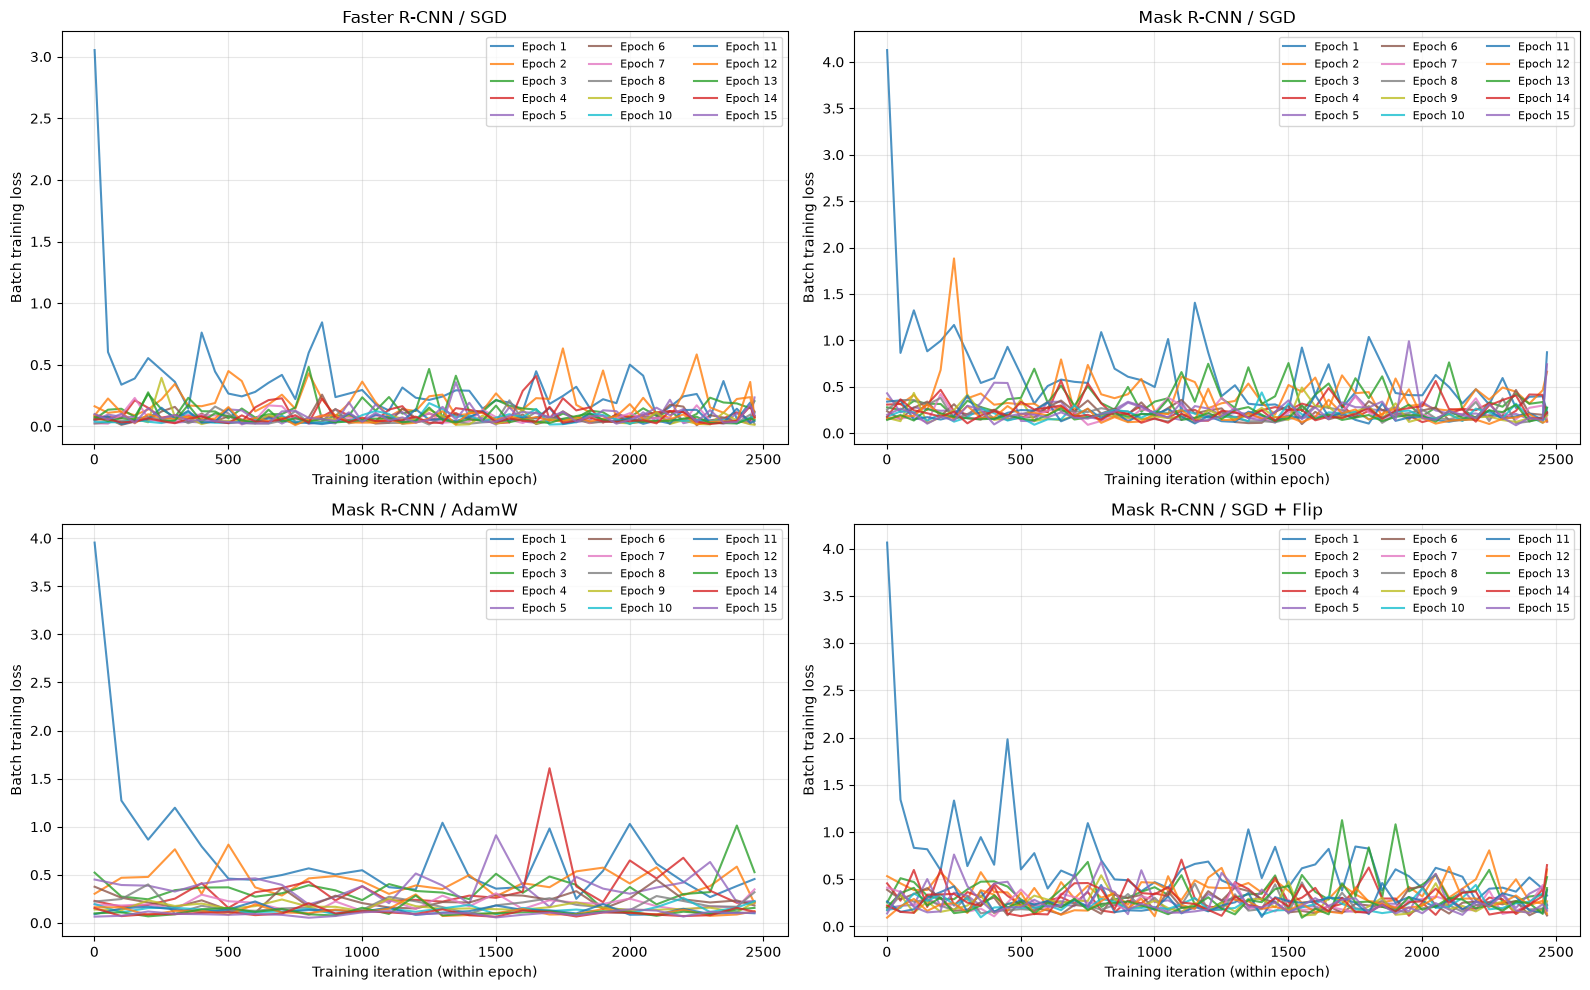

In [71]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

loss_dir = Path("evaluation_results")
loss_dir.mkdir(exist_ok=True)

batch_loss_history = {
    "Faster R-CNN / SGD": faster_batch_losses,
    "Mask R-CNN / SGD": sgd_batch_losses,
    "Mask R-CNN / AdamW": adamw_batch_losses,
    "Mask R-CNN / SGD + Flip": flip_batch_losses,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
batch_rows = []

for ax, (model_name, history) in zip(axes.flat, batch_loss_history.items()):
    for epoch_num in sorted({row[0] for row in history}):
        points = [(iteration, loss) for epoch, iteration, loss in history if epoch == epoch_num]
        iterations, losses = zip(*points)
        ax.plot(iterations, losses, label=f"Epoch {epoch_num}", alpha=0.8)

    batch_rows.extend(
        {"model": model_name, "epoch": epoch, "iteration": iteration, "loss": loss}
        for epoch, iteration, loss in history
    )
    ax.set_title(model_name)
    ax.set_xlabel("Training iteration (within epoch)")
    ax.set_ylabel("Batch training loss")
    ax.grid(alpha=0.3)
    ax.legend(ncol=3, fontsize=8)

plt.tight_layout()
plt.savefig(loss_dir / "loss_within_each_epoch.png", dpi=200)
plt.show()

pd.DataFrame(batch_rows).to_csv(loss_dir / "loss_within_each_epoch.csv", index=False)

average training loss per epoch

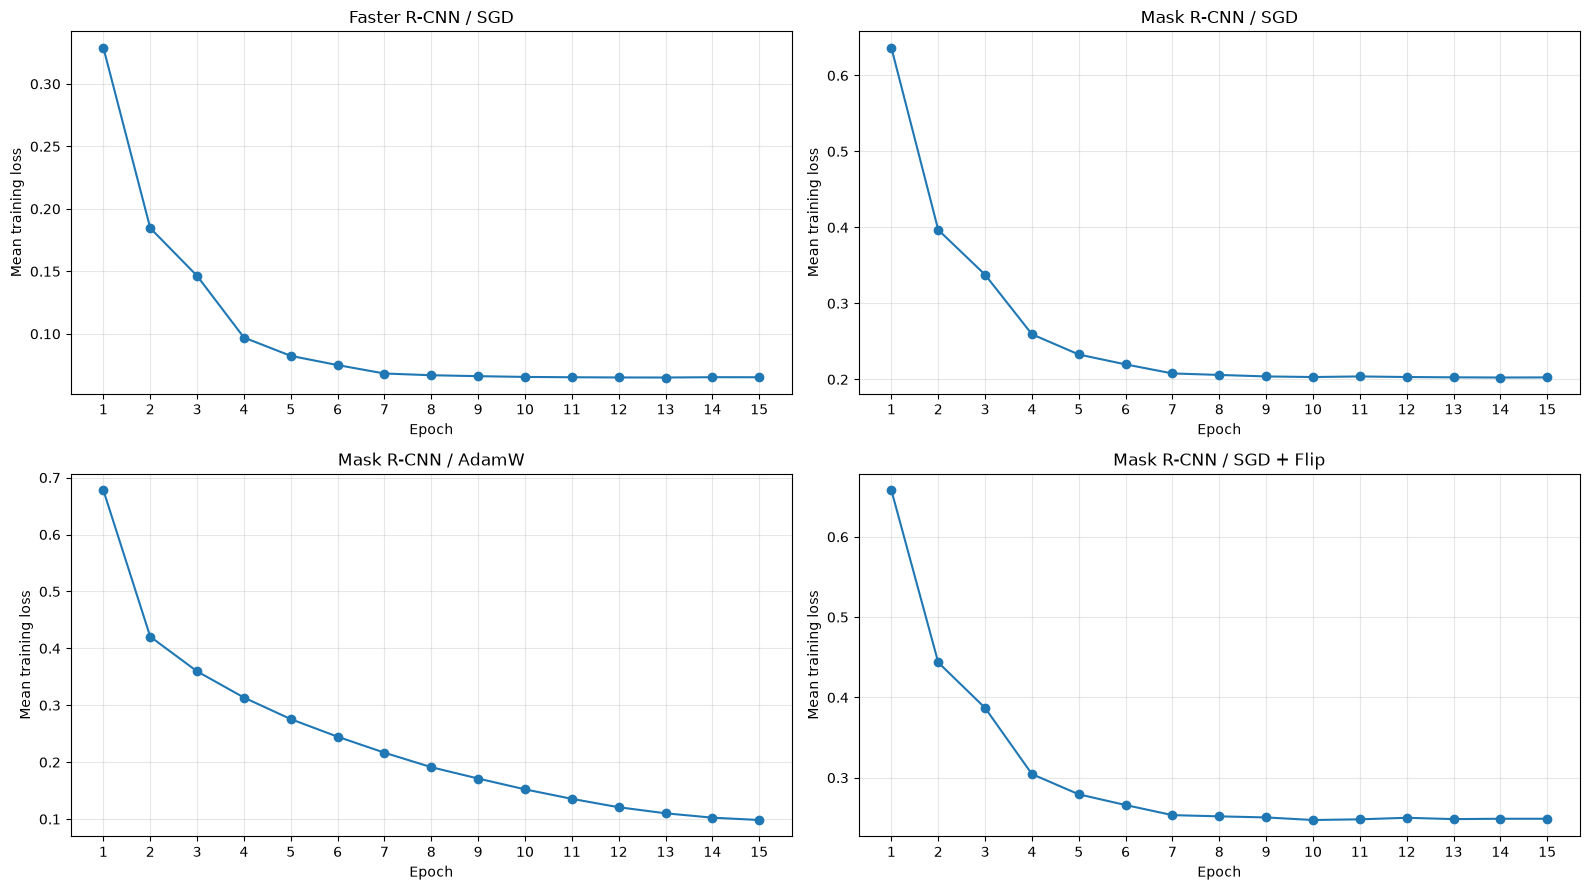

In [72]:
epoch_loss_history = {
    "Faster R-CNN / SGD": faster_epoch_losses,
    "Mask R-CNN / SGD": sgd_epoch_losses,
    "Mask R-CNN / AdamW": adamw_epoch_losses,
    "Mask R-CNN / SGD + Flip": flip_epoch_losses,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
epoch_rows = []

for ax, (model_name, losses) in zip(axes.flat, epoch_loss_history.items()):
    epochs = range(1, len(losses) + 1)
    ax.plot(epochs, losses, marker="o")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean training loss")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    epoch_rows.extend(
        {"model": model_name, "epoch": epoch, "mean_loss": loss}
        for epoch, loss in zip(epochs, losses)
    )

plt.tight_layout()
plt.savefig(loss_dir / "loss_by_epoch.png", dpi=200)
plt.show()

pd.DataFrame(epoch_rows).to_csv(loss_dir / "loss_by_epoch.csv", index=False)

Test dataset setup

In [73]:

image_dir_test = "instance_version/train"
annotation_file_test = "instance_version/instances_test.json"
category_id_test = COCO(annotation_file_test).getCatIds()
num_classes_test = len(category_id_test) + 1
dataset_test = MarineDataset(image_dir_test, annotation_file_test, category_id_test, transforms=get_transform(train=False))


data_loader_test = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn
)


loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


In [74]:

# Faster R-CNN Evaluation on Test Dataset

faster_model.eval()

faster_test_results = evaluate(
    model=faster_model,
    data_loader=data_loader_test,
    device=faster_device
)

print("Faster R-CNN test overed.")


creating index...
index created!
Test:  [   0/1003]  eta: 0:00:49  model_time: 0.0451 (0.0451)  evaluator_time: 0.0011 (0.0011)  time: 0.0489  data: 0.0024  max mem: 10054
Test:  [ 100/1003]  eta: 0:00:40  model_time: 0.0380 (0.0401)  evaluator_time: 0.0012 (0.0014)  time: 0.0436  data: 0.0027  max mem: 10054
Test:  [ 200/1003]  eta: 0:00:35  model_time: 0.0384 (0.0399)  evaluator_time: 0.0012 (0.0013)  time: 0.0439  data: 0.0024  max mem: 10054
Test:  [ 300/1003]  eta: 0:00:31  model_time: 0.0381 (0.0399)  evaluator_time: 0.0015 (0.0014)  time: 0.0445  data: 0.0031  max mem: 10054
Test:  [ 400/1003]  eta: 0:00:26  model_time: 0.0417 (0.0399)  evaluator_time: 0.0013 (0.0014)  time: 0.0449  data: 0.0030  max mem: 10054
Test:  [ 500/1003]  eta: 0:00:22  model_time: 0.0387 (0.0399)  evaluator_time: 0.0014 (0.0014)  time: 0.0446  data: 0.0029  max mem: 10054
Test:  [ 600/1003]  eta: 0:00:17  model_time: 0.0391 (0.0399)  evaluator_time: 0.0012 (0.0014)  time: 0.0442  data: 0.0028  max mem: 

In [75]:
base_model = load_baseline_model(device=device)
base_model.to(device=device)

MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         

In [76]:
torch.save(
    base_model.state_dict(),
    "maskrcnn_base.pth"
)

In [77]:
evaluater_base = evaluate(model=base_model, data_loader=data_loader_test, device=device)

creating index...
index created!
Test:  [   0/1003]  eta: 0:01:00  model_time: 0.0532 (0.0532)  evaluator_time: 0.0040 (0.0040)  time: 0.0599  data: 0.0023  max mem: 10054


/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1003]  eta: 0:00:54  model_time: 0.0459 (0.0502)  evaluator_time: 0.0048 (0.0073)  time: 0.0581  data: 0.0030  max mem: 10054
Test:  [ 200/1003]  eta: 0:00:47  model_time: 0.0467 (0.0494)  evaluator_time: 0.0060 (0.0070)  time: 0.0611  data: 0.0026  max mem: 10054
Test:  [ 300/1003]  eta: 0:00:41  model_time: 0.0477 (0.0493)  evaluator_time: 0.0068 (0.0071)  time: 0.0607  data: 0.0031  max mem: 10054
Test:  [ 400/1003]  eta: 0:00:36  model_time: 0.0462 (0.0494)  evaluator_time: 0.0037 (0.0073)  time: 0.0770  data: 0.0218  max mem: 10054
Test:  [ 500/1003]  eta: 0:00:30  model_time: 0.0455 (0.0499)  evaluator_time: 0.0044 (0.0076)  time: 0.0608  data: 0.0028  max mem: 10054
Test:  [ 600/1003]  eta: 0:00:25  model_time: 0.0484 (0.0505)  evaluator_time: 0.0072 (0.0080)  time: 0.0631  data: 0.0031  max mem: 10054
Test:  [ 700/1003]  eta: 0:00:18  model_time: 0.0455 (0.0503)  evaluator_time: 0.0044 (0.0079)  time: 0.0599  data: 0.0030  max mem: 10054
Test:  [ 800/1003]  eta: 0:

In [78]:
model = create_model(num_classes)
static_dict = torch.load("maskrcnn_sgd.pth", map_location=device)
model.load_state_dict(static_dict)
model.to(device=device)
model.eval()
evaluater_sgd = evaluate(model=model, data_loader=data_loader_test, device=device)

creating index...
index created!
Test:  [   0/1003]  eta: 0:00:55  model_time: 0.0494 (0.0494)  evaluator_time: 0.0030 (0.0030)  time: 0.0548  data: 0.0020  max mem: 10054


/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1003]  eta: 0:00:46  model_time: 0.0433 (0.0441)  evaluator_time: 0.0034 (0.0041)  time: 0.0508  data: 0.0029  max mem: 10054
Test:  [ 200/1003]  eta: 0:00:40  model_time: 0.0443 (0.0437)  evaluator_time: 0.0031 (0.0039)  time: 0.0499  data: 0.0026  max mem: 10054
Test:  [ 300/1003]  eta: 0:00:35  model_time: 0.0430 (0.0436)  evaluator_time: 0.0033 (0.0039)  time: 0.0507  data: 0.0030  max mem: 10054
Test:  [ 400/1003]  eta: 0:00:30  model_time: 0.0440 (0.0436)  evaluator_time: 0.0033 (0.0038)  time: 0.0515  data: 0.0029  max mem: 10054
Test:  [ 500/1003]  eta: 0:00:25  model_time: 0.0418 (0.0436)  evaluator_time: 0.0031 (0.0038)  time: 0.0495  data: 0.0027  max mem: 10054
Test:  [ 600/1003]  eta: 0:00:20  model_time: 0.0422 (0.0435)  evaluator_time: 0.0036 (0.0037)  time: 0.0498  data: 0.0029  max mem: 10054
Test:  [ 700/1003]  eta: 0:00:15  model_time: 0.0416 (0.0434)  evaluator_time: 0.0030 (0.0037)  time: 0.0497  data: 0.0029  max mem: 10054
Test:  [ 800/1003]  eta: 0:

In [79]:
model_adamw = create_model(num_classes)
static_dict = torch.load("maskrcnn_adamw.pth", map_location=device)
model_adamw.load_state_dict(static_dict)
model_adamw.to(device=device)
model_adamw.eval()
evaluater_adamw = evaluate(model=model_adamw, data_loader=data_loader_test, device=device)

creating index...
index created!
Test:  [   0/1003]  eta: 0:00:59  model_time: 0.0529 (0.0529)  evaluator_time: 0.0032 (0.0032)  time: 0.0590  data: 0.0026  max mem: 10054


/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1003]  eta: 0:00:45  model_time: 0.0425 (0.0439)  evaluator_time: 0.0024 (0.0032)  time: 0.0494  data: 0.0029  max mem: 10054
Test:  [ 200/1003]  eta: 0:00:39  model_time: 0.0423 (0.0433)  evaluator_time: 0.0025 (0.0030)  time: 0.0489  data: 0.0025  max mem: 10054
Test:  [ 300/1003]  eta: 0:00:34  model_time: 0.0420 (0.0432)  evaluator_time: 0.0028 (0.0030)  time: 0.0496  data: 0.0030  max mem: 10054
Test:  [ 400/1003]  eta: 0:00:29  model_time: 0.0450 (0.0432)  evaluator_time: 0.0027 (0.0030)  time: 0.0503  data: 0.0030  max mem: 10054
Test:  [ 500/1003]  eta: 0:00:24  model_time: 0.0419 (0.0432)  evaluator_time: 0.0020 (0.0030)  time: 0.0482  data: 0.0026  max mem: 10054
Test:  [ 600/1003]  eta: 0:00:19  model_time: 0.0414 (0.0431)  evaluator_time: 0.0026 (0.0029)  time: 0.0486  data: 0.0028  max mem: 10054
Test:  [ 700/1003]  eta: 0:00:14  model_time: 0.0413 (0.0430)  evaluator_time: 0.0027 (0.0029)  time: 0.0484  data: 0.0029  max mem: 10054
Test:  [ 800/1003]  eta: 0:

In [80]:
model_sgd_trans = create_model(num_classes)
static_dict = torch.load("maskrcnn_sgd_trans.pth", map_location=device)
model_sgd_trans.load_state_dict(static_dict)
model_sgd_trans.to(device=device)
model_sgd_trans.eval()
evaluater_sgd_trans = evaluate(model=model_sgd_trans, data_loader=data_loader_test, device=device)

creating index...
index created!
Test:  [   0/1003]  eta: 0:00:53  model_time: 0.0483 (0.0483)  evaluator_time: 0.0022 (0.0022)  time: 0.0529  data: 0.0021  max mem: 10054


/tmp/ipykernel_2267/3555529500.py:107: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks


Test:  [ 100/1003]  eta: 0:00:47  model_time: 0.0433 (0.0450)  evaluator_time: 0.0036 (0.0047)  time: 0.0524  data: 0.0028  max mem: 10054
Test:  [ 200/1003]  eta: 0:00:42  model_time: 0.0436 (0.0446)  evaluator_time: 0.0032 (0.0045)  time: 0.0512  data: 0.0026  max mem: 10054
Test:  [ 300/1003]  eta: 0:00:36  model_time: 0.0431 (0.0445)  evaluator_time: 0.0041 (0.0045)  time: 0.0511  data: 0.0030  max mem: 10054
Test:  [ 400/1003]  eta: 0:00:31  model_time: 0.0480 (0.0446)  evaluator_time: 0.0038 (0.0045)  time: 0.0570  data: 0.0035  max mem: 10054
Test:  [ 500/1003]  eta: 0:00:26  model_time: 0.0436 (0.0445)  evaluator_time: 0.0032 (0.0045)  time: 0.0512  data: 0.0027  max mem: 10054
Test:  [ 600/1003]  eta: 0:00:21  model_time: 0.0440 (0.0446)  evaluator_time: 0.0040 (0.0045)  time: 0.0537  data: 0.0030  max mem: 10054
Test:  [ 700/1003]  eta: 0:00:15  model_time: 0.0418 (0.0446)  evaluator_time: 0.0032 (0.0045)  time: 0.0506  data: 0.0030  max mem: 10054
Test:  [ 800/1003]  eta: 0:

### 5.2 Evaluation Metrics

In [84]:
from IPython.display import display, Image
import matplotlib.pyplot as plt
# from help_funciton.evaluation import export_evaluation_results, plot_predictions, summarize_evaluators

evaluators = {
    "Faster R-CNN / SGD": faster_test_results,
    "Mask R-CNN / Baseline": evaluater_base,
    "Mask R-CNN / SGD": evaluater_sgd,
    "Mask R-CNN / AdamW": evaluater_adamw,
    "Mask R-CNN / SGD + Transforms": evaluater_sgd_trans,
}

import pickle

with open("evaluators.pkl", "wb") as f:
    pickle.dump(evaluators, f)
    

In [85]:
import pickle
with open("evaluators.pkl", "rb") as f:
    evaluators = pickle.load(f)
    
class_names = {
    dataset_test.cat_to_label[c["id"]]: c["name"]
    for c in dataset_test.coco.dataset["categories"]
}

summary = summarize_evaluators(evaluators)
display(summary.round(4))

,model,iou_type,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
0,Faster R-CNN / SGD,bbox,0.0583,0.0887,0.0603,0.1047,0.0662,0.1287,0.1324,0.1511,0.1511,0.1993,0.1459,0.2079
1,Mask R-CNN / Baseline,bbox,0.0012,0.0021,0.0011,0.0000,0.0014,0.0254,0.0032,0.0052,0.0059,0.0000,0.0088,0.0340
2,Mask R-CNN / Baseline,segm,0.0009,0.0020,0.0009,0.0000,0.0016,0.0206,0.0028,0.0034,0.0034,0.0000,0.0110,0.0243
3,Mask R-CNN / SGD,bbox,0.0628,0.1000,0.0678,0.1280,0.0711,0.1159,0.1305,0.1485,0.1485,0.2381,0.1556,0.1791
4,Mask R-CNN / SGD,segm,0.0574,0.1043,0.0546,0.1048,0.0684,0.0992,0.1187,0.1295,0.1295,0.2112,0.1445,0.1370
5,Mask R-CNN / AdamW,bbox,0.0485,0.0726,0.0530,0.0820,0.0550,0.0830,0.1035,0.1157,0.1157,0.1522,0.1207,0.1267
6,Mask R-CNN / AdamW,segm,0.0416,0.0805,0.0383,0.0608,0.0446,0.0836,0.0920,0.1019,0.1019,0.1332,0.1081,0.1098
7,Mask R-CNN / SGD + Transforms,bbox,0.0859,0.1285,0.0904,0.1407,0.0823,0.1650,0.1734,0.2060,0.2060,0.2782,0.1756,0.3060
8,Mask R-CNN / SGD + Transforms,segm,0.0685,0.1255,0.0662,0.1014,0.0646,0.1617,0.1308,0.1458,0.1458,0.2281,0.1307,0.2133


## 6. Results

### 6.1 Quantitative Results

In [86]:
report = export_evaluation_results(evaluators, "evaluation_results", class_names)
display(report["summary"].round(4))
display(report["per_class"].round(4))


,model,iou_type,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR1,AR10,AR100,AR_small,AR_medium,AR_large
0,Faster R-CNN / SGD,bbox,0.0583,0.0887,0.0603,0.1047,0.0662,0.1287,0.1324,0.1511,0.1511,0.1993,0.1459,0.2079
1,Mask R-CNN / Baseline,bbox,0.0012,0.0021,0.0011,0.0000,0.0014,0.0254,0.0032,0.0052,0.0059,0.0000,0.0088,0.0340
2,Mask R-CNN / Baseline,segm,0.0009,0.0020,0.0009,0.0000,0.0016,0.0206,0.0028,0.0034,0.0034,0.0000,0.0110,0.0243
3,Mask R-CNN / SGD,bbox,0.0628,0.1000,0.0678,0.1280,0.0711,0.1159,0.1305,0.1485,0.1485,0.2381,0.1556,0.1791
4,Mask R-CNN / SGD,segm,0.0574,0.1043,0.0546,0.1048,0.0684,0.0992,0.1187,0.1295,0.1295,0.2112,0.1445,0.1370
5,Mask R-CNN / AdamW,bbox,0.0485,0.0726,0.0530,0.0820,0.0550,0.0830,0.1035,0.1157,0.1157,0.1522,0.1207,0.1267
6,Mask R-CNN / AdamW,segm,0.0416,0.0805,0.0383,0.0608,0.0446,0.0836,0.0920,0.1019,0.1019,0.1332,0.1081,0.1098
7,Mask R-CNN / SGD + Transforms,bbox,0.0859,0.1285,0.0904,0.1407,0.0823,0.1650,0.1734,0.2060,0.2060,0.2782,0.1756,0.3060
8,Mask R-CNN / SGD + Transforms,segm,0.0685,0.1255,0.0662,0.1014,0.0646,0.1617,0.1308,0.1458,0.1458,0.2281,0.1307,0.2133


,iou_type,category_id,class_name,gt_instances,gt_images,AP,AP50,AR100,model
0,bbox,1,rov,492,447,0.4741,0.6902,0.6772,Faster R-CNN / SGD
1,bbox,2,plant,30,23,0.0469,0.1135,0.1300,Faster R-CNN / SGD
2,bbox,3,animal_fish,39,26,0.1096,0.1743,0.3590,Faster R-CNN / SGD
3,bbox,4,animal_starfish,7,4,0.0214,0.0442,0.1429,Faster R-CNN / SGD
4,bbox,5,animal_shells,22,18,0.0000,0.0000,0.0000,Faster R-CNN / SGD
...,...,...,...,...,...,...,...,...,...
193,segm,18,trash_branch,37,24,0.0038,0.0062,0.1270,Mask R-CNN / SGD + Transforms
194,segm,19,trash_wreckage,3,3,0.0000,0.0000,0.0000,Mask R-CNN / SGD + Transforms
195,segm,20,trash_tarp,2,2,0.0014,0.0144,0.0500,Mask R-CNN / SGD + Transforms
196,segm,21,trash_rope,43,43,0.0016,0.0048,0.0233,Mask R-CNN / SGD + Transforms


### 6.2 Qualitative Results

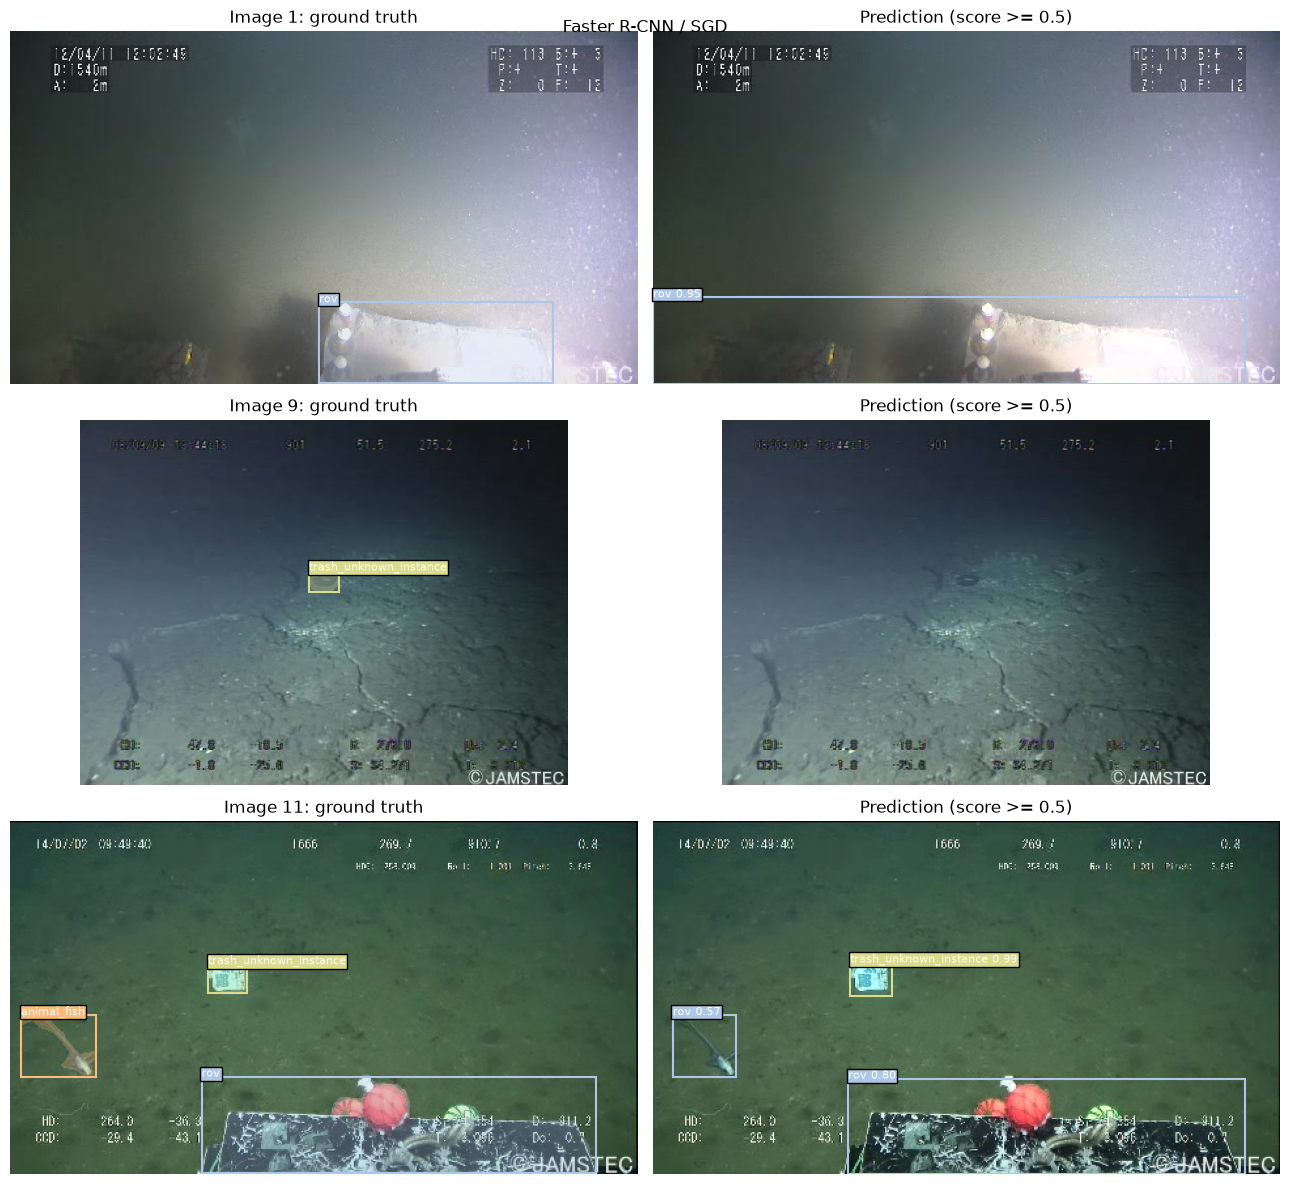

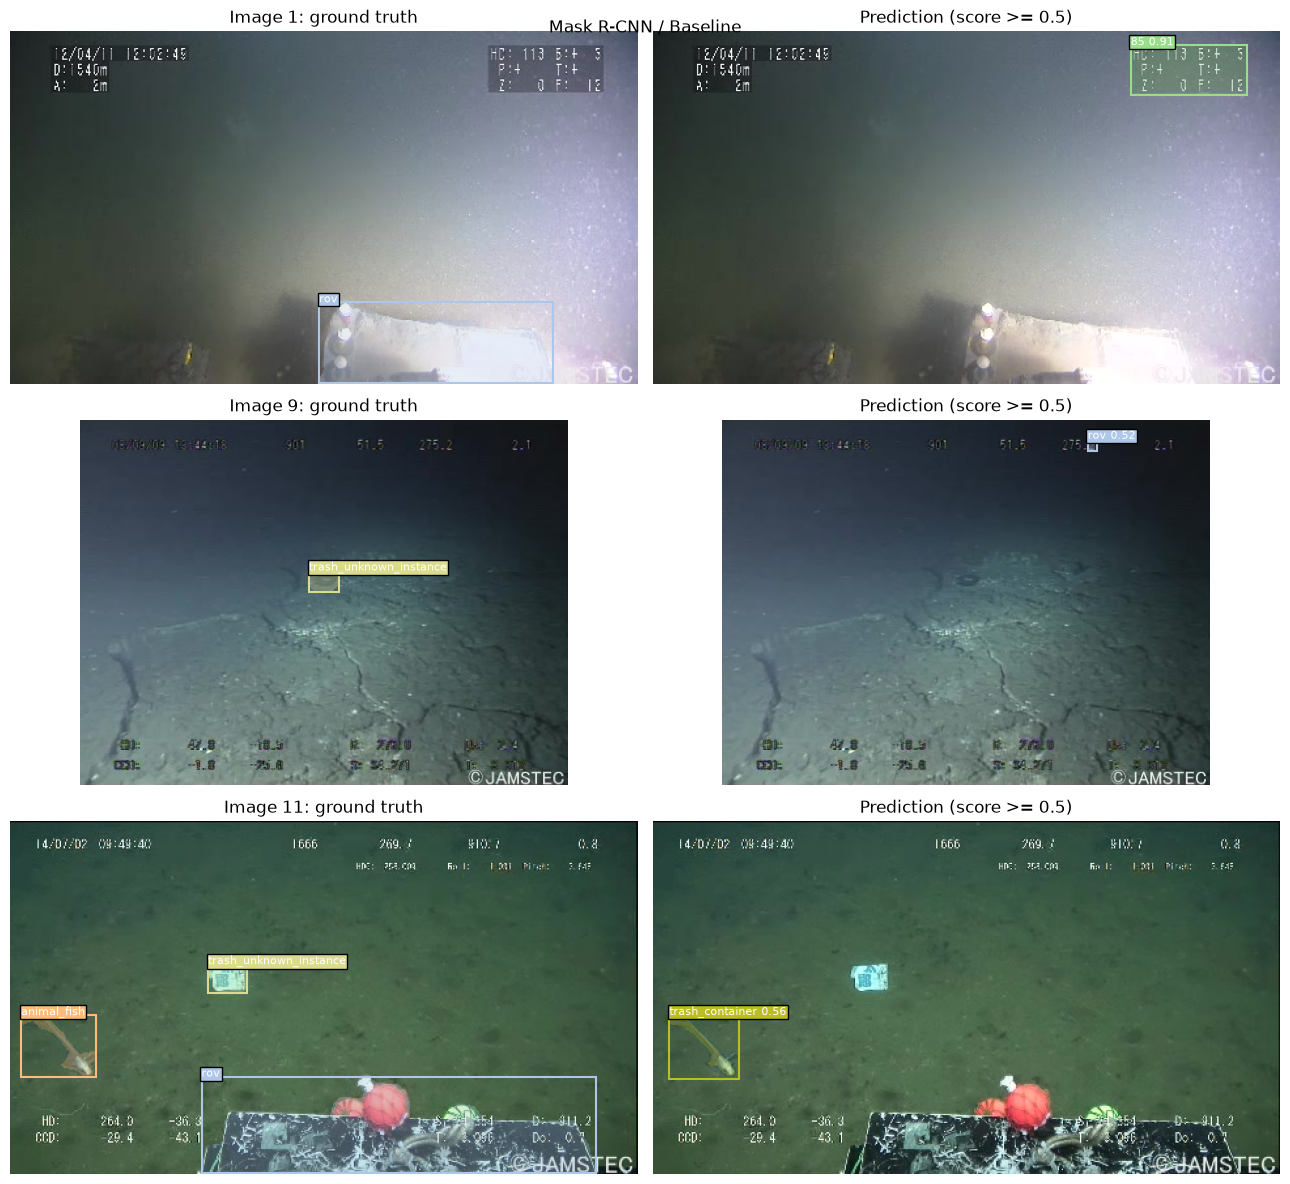

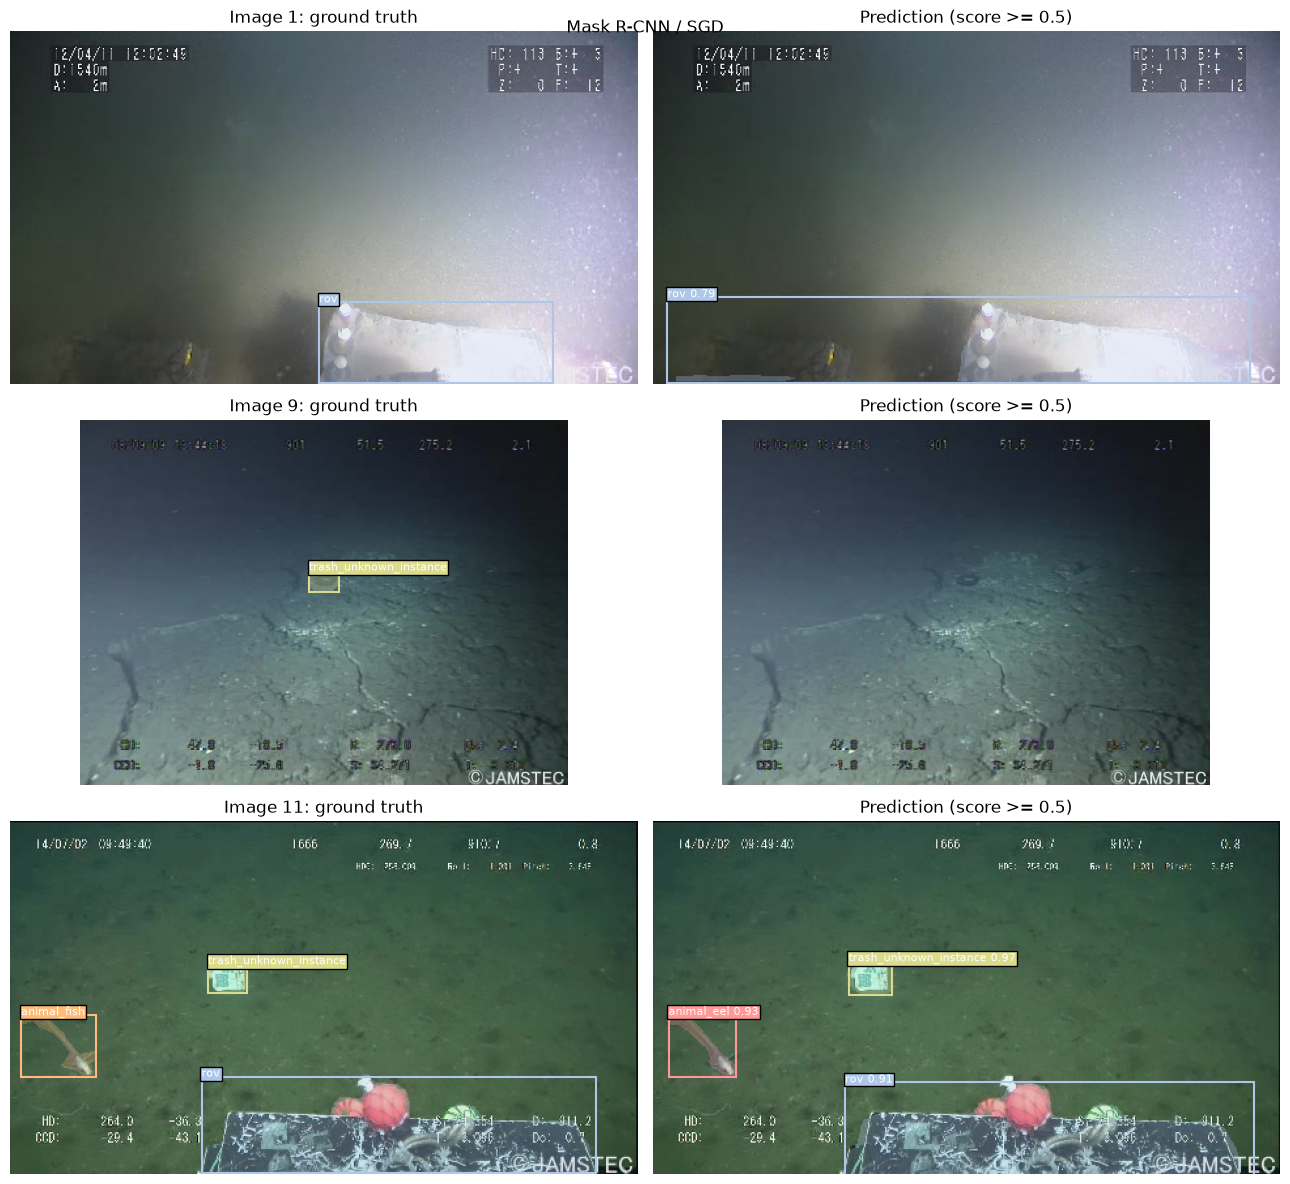

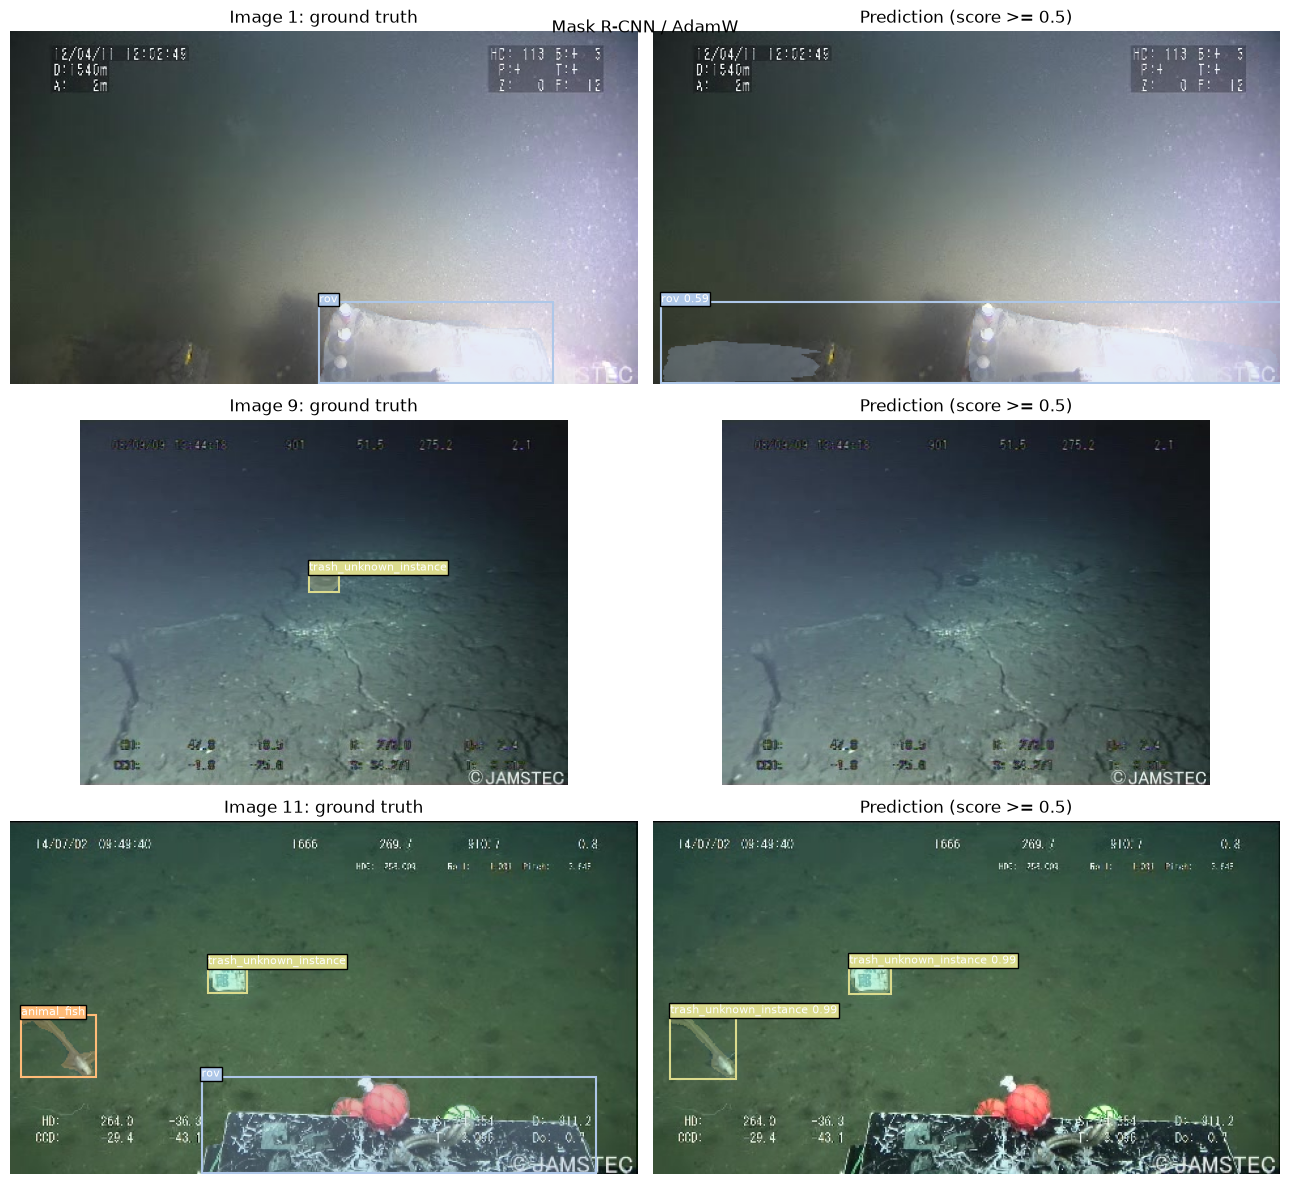

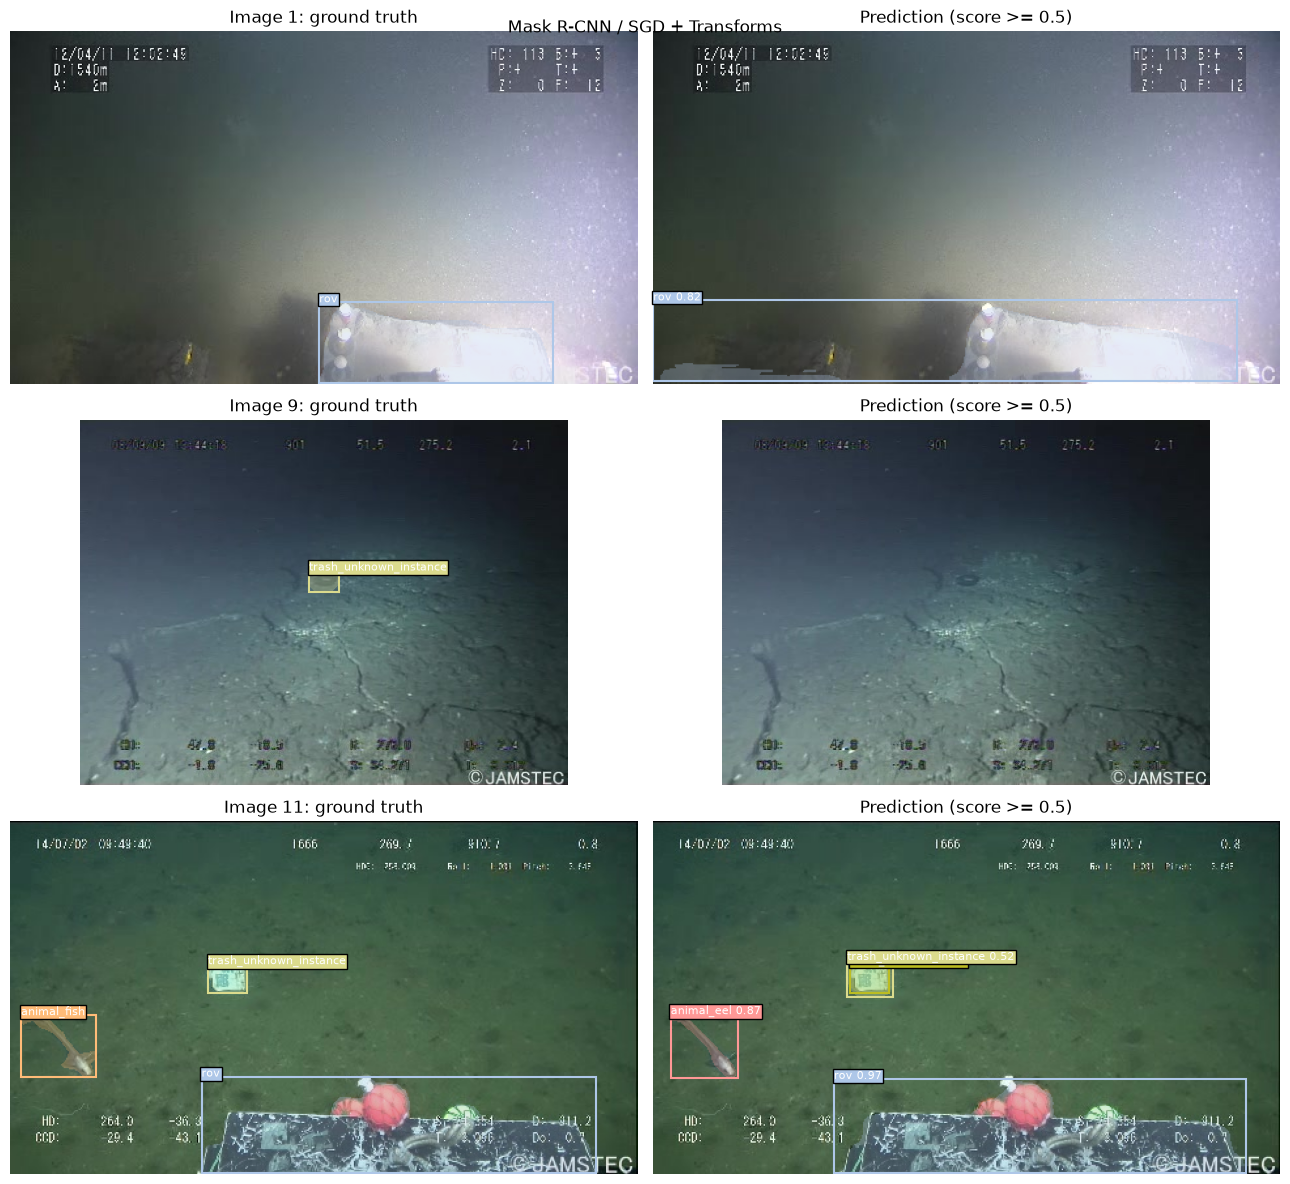

In [89]:
models = {
    "Faster R-CNN / SGD": (faster_model, faster_device),
    "Mask R-CNN / Baseline": (base_model, device),
    "Mask R-CNN / SGD": (model, device),
    "Mask R-CNN / AdamW": (model_adamw, device),
    "Mask R-CNN / SGD + Transforms": (model_sgd_trans, device),
}

for i, (name, (trained_model, model_device)) in enumerate(models.items(), 1):
    fig = plot_predictions(
        trained_model,
        dataset_test,
        model_device,
        class_names,
    )
    fig.suptitle(name)
    fig.savefig(f"evaluation_results/predictions_{i}.png", bbox_inches="tight", dpi=160)
    display(fig)
    plt.close(fig)

### 6.3 Model Comparison

## 7. Discussion

### 7.1 Error Analysis and Limitations

## 8. Conclusion and Future Work

## References

## Help Function

 evaluation

In [53]:

from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import torch



METRICS = (
    "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large",
    "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large",
)


def _valid_mean(values):
    values = np.asarray(values)
    values = values[values >= 0]
    return values.mean() if len(values) else np.nan


def summarize_evaluators(evaluators):
    rows = []
    for name, evaluator in evaluators.items():
        for iou_type, result in evaluator.coco_eval.items():
            row = {"model": name, "iou_type": iou_type}
            row.update(zip(METRICS, np.where(result.stats >= 0, result.stats, np.nan)))
            rows.append(row)
    return pd.DataFrame(rows)


def per_class_metrics(evaluator, class_names):
    rows = []
    for iou_type, result in evaluator.coco_eval.items():
        params = result.eval["params"]
        precision = result.eval["precision"]
        recall = result.eval["recall"]
        area = list(params.areaRngLbl).index("all")
        detections = list(params.maxDets).index(100)
        iou50 = np.flatnonzero(np.isclose(params.iouThrs, 0.5))[0]
        ground_truth = result.cocoGt.dataset["annotations"]
        for index, category_id in enumerate(params.catIds):
            anns = [a for a in ground_truth if a["category_id"] == category_id
                    and a["image_id"] in params.imgIds and not a.get("iscrowd", 0)]
            rows.append({
                "iou_type": iou_type,
                "category_id": category_id,
                "class_name": class_names[category_id],
                "gt_instances": len(anns),
                "gt_images": len({a["image_id"] for a in anns}),
                "AP": _valid_mean(precision[:, :, index, area, detections]),
                "AP50": _valid_mean(precision[iou50, :, index, area, detections]),
                "AR100": _valid_mean(recall[:, index, area, detections]),
            })
    return pd.DataFrame(rows)


def plot_precision_recall(evaluator, class_names, iou_type="bbox"):
    result = evaluator.coco_eval[iou_type]
    params = result.eval["params"]
    area = list(params.areaRngLbl).index("all")
    detections = list(params.maxDets).index(100)
    iou50 = np.flatnonzero(np.isclose(params.iouThrs, 0.5))[0]
    precision = result.eval["precision"][iou50, :, :, area, detections]
    fig, ax = plt.subplots(figsize=(9, 5))
    for index, category_id in enumerate(params.catIds):
        values = precision[:, index]
        valid = values >= 0
        if valid.any():
            ax.plot(params.recThrs[valid], values[valid], label=class_names[category_id])
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02),
           title=f"{iou_type} precision-recall (IoU=0.50)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    return fig


def plot_model_comparison(summary):
    types = summary["iou_type"].unique()
    fig, axes = plt.subplots(1, len(types), figsize=(7 * len(types), 4), squeeze=False)
    for ax, iou_type in zip(axes[0], types):
        rows = summary[summary["iou_type"] == iou_type]
        x = np.arange(len(rows))
        ax.bar(x - 0.18, rows["mAP"], width=0.36, label="mAP")
        ax.bar(x + 0.18, rows["AP50"], width=0.36, label="AP50")
        ax.set_xticks(x, rows["model"], rotation=20, ha="right")
        ax.set(ylabel="Average precision", ylim=(0, 1.05), title=iou_type)
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    return fig


def _draw_instances(ax, image, objects, class_names, predictions=False):
    ax.imshow(image.detach().cpu().permute(1, 2, 0))
    labels = objects["labels"].detach().cpu().numpy()
    boxes = objects["boxes"].detach().cpu().numpy()
    masks = objects.get("masks")
    if masks is not None:
        masks = masks.detach().cpu().numpy()
    for index, (label, box) in enumerate(zip(labels, boxes)):
        color = plt.get_cmap("tab20")(int(label) % 20)
        if masks is not None:
            mask = masks[index].squeeze() > 0.5
            overlay = np.zeros((*mask.shape, 4))
            overlay[..., :3] = color[:3]
            overlay[..., 3] = mask * 0.3
            ax.imshow(overlay)
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               edgecolor=color, facecolor="none", linewidth=1.5))
        caption = class_names.get(int(label), str(label))
        if predictions:
            caption += f" {objects['scores'][index]:.2f}"
        ax.text(x1, y1, caption, color="white", fontsize=8,
                bbox={"facecolor": color, "pad": 1})
    ax.axis("off")


@torch.inference_mode()
def plot_predictions(model, dataset, device, class_names, indices=(0, 1, 2), score_threshold=0.5):
    model.eval()
    fig, axes = plt.subplots(len(indices), 2, figsize=(13, 4 * len(indices)), squeeze=False)
    for row, index in enumerate(indices):
        image, target = dataset[index]
        prediction = {key: value.cpu() for key, value in model([image.to(device)])[0].items()}
        keep = prediction["scores"] >= score_threshold
        prediction = {key: value[keep] for key, value in prediction.items()}
        _draw_instances(axes[row, 0], image, target, class_names)
        _draw_instances(axes[row, 1], image, prediction, class_names, predictions=True)
        axes[row, 0].set_title(f"Image {target['image_id']}: ground truth")
        axes[row, 1].set_title(f"Prediction (score >= {score_threshold})")
    fig.tight_layout()
    return fig


def export_evaluation_results(evaluators, output_dir, class_names):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    summary = summarize_evaluators(evaluators)
    per_class = pd.concat([
        per_class_metrics(evaluator, class_names).assign(model=name)
        for name, evaluator in evaluators.items()
    ], ignore_index=True)
    summary.to_csv(output_dir / "summary.csv", index=False)
    per_class.to_csv(output_dir / "per_class_metrics.csv", index=False)
    fig = plot_model_comparison(summary)
    fig.savefig(output_dir / "model_comparison.png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    for index, (name, evaluator) in enumerate(evaluators.items(), start=1):
        stem = re.sub(r"[^A-Za-z0-9_-]+", "_", name).strip("_")
        for iou_type in evaluator.coco_eval:
            fig = plot_precision_recall(evaluator, class_names, iou_type)
            fig.savefig(output_dir / f"{index:02d}_{stem}_{iou_type}_pr.png",
                        dpi=160, bbox_inches="tight")
            plt.close(fig)
    return {"summary": summary, "per_class": per_class}


utils.py

In [54]:
import datetime
import errno
import os
import time
from collections import defaultdict, deque

import torch
import torch.distributed as dist


class SmoothedValue:
    """Track a series of values and provide access to smoothed values over a
    window or the global series average.
    """

    def __init__(self, window_size=20, fmt=None):
        if fmt is None:
            fmt = "{median:.4f} ({global_avg:.4f})"
        self.deque = deque(maxlen=window_size)
        self.total = 0.0
        self.count = 0
        self.fmt = fmt

    def update(self, value, n=1):
        self.deque.append(value)
        self.count += n
        self.total += value * n

    def synchronize_between_processes(self):
        """
        Warning: does not synchronize the deque!
        """
        if not is_dist_avail_and_initialized():
            return
        t = torch.tensor([self.count, self.total], dtype=torch.float64, device="cuda")
        dist.barrier()
        dist.all_reduce(t)
        t = t.tolist()
        self.count = int(t[0])
        self.total = t[1]

    @property
    def median(self):
        d = torch.tensor(list(self.deque))
        return d.median().item()

    @property
    def avg(self):
        d = torch.tensor(list(self.deque), dtype=torch.float32)
        return d.mean().item()

    @property
    def global_avg(self):
        return self.total / self.count

    @property
    def max(self):
        return max(self.deque)

    @property
    def value(self):
        return self.deque[-1]

    def __str__(self):
        return self.fmt.format(
            median=self.median, avg=self.avg, global_avg=self.global_avg, max=self.max, value=self.value
        )


def all_gather(data):
    """
    Run all_gather on arbitrary picklable data (not necessarily tensors)
    Args:
        data: any picklable object
    Returns:
        list[data]: list of data gathered from each rank
    """
    world_size = get_world_size()
    if world_size == 1:
        return [data]
    data_list = [None] * world_size
    dist.all_gather_object(data_list, data)
    return data_list


def reduce_dict(input_dict, average=True):
    """
    Args:
        input_dict (dict): all the values will be reduced
        average (bool): whether to do average or sum
    Reduce the values in the dictionary from all processes so that all processes
    have the averaged results. Returns a dict with the same fields as
    input_dict, after reduction.
    """
    world_size = get_world_size()
    if world_size < 2:
        return input_dict
    with torch.inference_mode():
        names = []
        values = []
        # sort the keys so that they are consistent across processes
        for k in sorted(input_dict.keys()):
            names.append(k)
            values.append(input_dict[k])
        values = torch.stack(values, dim=0)
        dist.all_reduce(values)
        if average:
            values /= world_size
        reduced_dict = {k: v for k, v in zip(names, values)}
    return reduced_dict


class MetricLogger:
    def __init__(self, delimiter="\t"):
        self.meters = defaultdict(SmoothedValue)
        self.delimiter = delimiter

    def update(self, **kwargs):
        for k, v in kwargs.items():
            if isinstance(v, torch.Tensor):
                v = v.item()
            assert isinstance(v, (float, int))
            self.meters[k].update(v)

    def __getattr__(self, attr):
        if attr in self.meters:
            return self.meters[attr]
        if attr in self.__dict__:
            return self.__dict__[attr]
        raise AttributeError(f"'{type(self).__name__}' object has no attribute '{attr}'")

    def __str__(self):
        loss_str = []
        for name, meter in self.meters.items():
            loss_str.append(f"{name}: {str(meter)}")
        return self.delimiter.join(loss_str)

    def synchronize_between_processes(self):
        for meter in self.meters.values():
            meter.synchronize_between_processes()

    def add_meter(self, name, meter):
        self.meters[name] = meter

    def log_every(self, iterable, print_freq, header=None):
        i = 0
        if not header:
            header = ""
        start_time = time.time()
        end = time.time()
        iter_time = SmoothedValue(fmt="{avg:.4f}")
        data_time = SmoothedValue(fmt="{avg:.4f}")
        space_fmt = ":" + str(len(str(len(iterable)))) + "d"
        if torch.cuda.is_available():
            log_msg = self.delimiter.join(
                [
                    header,
                    "[{0" + space_fmt + "}/{1}]",
                    "eta: {eta}",
                    "{meters}",
                    "time: {time}",
                    "data: {data}",
                    "max mem: {memory:.0f}",
                ]
            )
        else:
            log_msg = self.delimiter.join(
                [header, "[{0" + space_fmt + "}/{1}]", "eta: {eta}", "{meters}", "time: {time}", "data: {data}"]
            )
        MB = 1024.0 * 1024.0
        for obj in iterable:
            data_time.update(time.time() - end)
            yield obj
            iter_time.update(time.time() - end)
            if i % print_freq == 0 or i == len(iterable) - 1:
                eta_seconds = iter_time.global_avg * (len(iterable) - i)
                eta_string = str(datetime.timedelta(seconds=int(eta_seconds)))
                if torch.cuda.is_available():
                    print(
                        log_msg.format(
                            i,
                            len(iterable),
                            eta=eta_string,
                            meters=str(self),
                            time=str(iter_time),
                            data=str(data_time),
                            memory=torch.cuda.max_memory_allocated() / MB,
                        )
                    )
                else:
                    print(
                        log_msg.format(
                            i, len(iterable), eta=eta_string, meters=str(self), time=str(iter_time), data=str(data_time)
                        )
                    )
            i += 1
            end = time.time()
        total_time = time.time() - start_time
        total_time_str = str(datetime.timedelta(seconds=int(total_time)))
        print(f"{header} Total time: {total_time_str} ({total_time / len(iterable):.4f} s / it)")


def collate_fn(batch):
    return tuple(zip(*batch))


def mkdir(path):
    try:
        os.makedirs(path)
    except OSError as e:
        if e.errno != errno.EEXIST:
            raise


def setup_for_distributed(is_master):
    """
    This function disables printing when not in master process
    """
    import builtins as __builtin__

    builtin_print = __builtin__.print

    def print(*args, **kwargs):
        force = kwargs.pop("force", False)
        if is_master or force:
            builtin_print(*args, **kwargs)

    __builtin__.print = print


def is_dist_avail_and_initialized():
    if not dist.is_available():
        return False
    if not dist.is_initialized():
        return False
    return True


def get_world_size():
    if not is_dist_avail_and_initialized():
        return 1
    return dist.get_world_size()


def get_rank():
    if not is_dist_avail_and_initialized():
        return 0
    return dist.get_rank()


def is_main_process():
    return get_rank() == 0


def save_on_master(*args, **kwargs):
    if is_main_process():
        torch.save(*args, **kwargs)


def init_distributed_mode(args):
    if "RANK" in os.environ and "WORLD_SIZE" in os.environ:
        args.rank = int(os.environ["RANK"])
        args.world_size = int(os.environ["WORLD_SIZE"])
        args.gpu = int(os.environ["LOCAL_RANK"])
    elif "SLURM_PROCID" in os.environ:
        args.rank = int(os.environ["SLURM_PROCID"])
        args.gpu = args.rank % torch.cuda.device_count()
    else:
        print("Not using distributed mode")
        args.distributed = False
        return

    args.distributed = True

    torch.cuda.set_device(args.gpu)
    args.dist_backend = "nccl"
    print(f"| distributed init (rank {args.rank}): {args.dist_url}", flush=True)
    torch.distributed.init_process_group(
        backend=args.dist_backend, init_method=args.dist_url, world_size=args.world_size, rank=args.rank
    )
    torch.distributed.barrier()
    setup_for_distributed(args.rank == 0)

coco_eval.py

In [55]:
import copy
import io
from contextlib import redirect_stdout

import numpy as np
import pycocotools.mask as mask_util
import torch

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


class CocoEvaluator:
    def __init__(self, coco_gt, iou_types):
        if not isinstance(iou_types, (list, tuple)):
            raise TypeError(f"This constructor expects iou_types of type list or tuple, instead  got {type(iou_types)}")
        coco_gt = copy.deepcopy(coco_gt)
        self.coco_gt = coco_gt

        self.iou_types = iou_types
        self.coco_eval = {}
        for iou_type in iou_types:
            self.coco_eval[iou_type] = COCOeval(coco_gt, iouType=iou_type)

        self.img_ids = []
        self.eval_imgs = {k: [] for k in iou_types}

    def update(self, predictions):
        img_ids = list(np.unique(list(predictions.keys())))
        self.img_ids.extend(img_ids)

        for iou_type in self.iou_types:
            results = self.prepare(predictions, iou_type)
            with redirect_stdout(io.StringIO()):
                coco_dt = COCO.loadRes(self.coco_gt, results) if results else COCO()
            coco_eval = self.coco_eval[iou_type]

            coco_eval.cocoDt = coco_dt
            coco_eval.params.imgIds = list(img_ids)
            img_ids, eval_imgs = evaluate_coco(coco_eval)

            self.eval_imgs[iou_type].append(eval_imgs)

    def synchronize_between_processes(self):
        for iou_type in self.iou_types:
            self.eval_imgs[iou_type] = np.concatenate(self.eval_imgs[iou_type], 2)
            create_common_coco_eval(self.coco_eval[iou_type], self.img_ids, self.eval_imgs[iou_type])

    def accumulate(self):
        for coco_eval in self.coco_eval.values():
            coco_eval.accumulate()

    def summarize(self):
        for iou_type, coco_eval in self.coco_eval.items():
            print(f"IoU metric: {iou_type}")
            coco_eval.summarize()

    def prepare(self, predictions, iou_type):
        if iou_type == "bbox":
            return self.prepare_for_coco_detection(predictions)
        if iou_type == "segm":
            return self.prepare_for_coco_segmentation(predictions)
        if iou_type == "keypoints":
            return self.prepare_for_coco_keypoint(predictions)
        raise ValueError(f"Unknown iou type {iou_type}")

    def prepare_for_coco_detection(self, predictions):
        coco_results = []
        for original_id, prediction in predictions.items():
            if len(prediction) == 0:
                continue

            boxes = prediction["boxes"]
            boxes = convert_to_xywh(boxes).tolist()
            scores = prediction["scores"].tolist()
            labels = prediction["labels"].tolist()

            coco_results.extend(
                [
                    {
                        "image_id": original_id,
                        "category_id": labels[k],
                        "bbox": box,
                        "score": scores[k],
                    }
                    for k, box in enumerate(boxes)
                ]
            )
        return coco_results

    def prepare_for_coco_segmentation(self, predictions):
        coco_results = []
        for original_id, prediction in predictions.items():
            if len(prediction) == 0:
                continue

            scores = prediction["scores"]
            labels = prediction["labels"]
            masks = prediction["masks"]

            masks = masks > 0.5

            scores = prediction["scores"].tolist()
            labels = prediction["labels"].tolist()

            rles = [
                mask_util.encode(np.array(mask[0, :, :, np.newaxis], dtype=np.uint8, order="F"))[0] for mask in masks
            ]
            for rle in rles:
                rle["counts"] = rle["counts"].decode("utf-8")

            coco_results.extend(
                [
                    {
                        "image_id": original_id,
                        "category_id": labels[k],
                        "segmentation": rle,
                        "score": scores[k],
                    }
                    for k, rle in enumerate(rles)
                ]
            )
        return coco_results

    def prepare_for_coco_keypoint(self, predictions):
        coco_results = []
        for original_id, prediction in predictions.items():
            if len(prediction) == 0:
                continue

            boxes = prediction["boxes"]
            boxes = convert_to_xywh(boxes).tolist()
            scores = prediction["scores"].tolist()
            labels = prediction["labels"].tolist()
            keypoints = prediction["keypoints"]
            keypoints = keypoints.flatten(start_dim=1).tolist()

            coco_results.extend(
                [
                    {
                        "image_id": original_id,
                        "category_id": labels[k],
                        "keypoints": keypoint,
                        "score": scores[k],
                    }
                    for k, keypoint in enumerate(keypoints)
                ]
            )
        return coco_results


def convert_to_xywh(boxes):
    xmin, ymin, xmax, ymax = boxes.unbind(1)
    return torch.stack((xmin, ymin, xmax - xmin, ymax - ymin), dim=1)


def merge(img_ids, eval_imgs):
    all_img_ids = all_gather(img_ids)
    all_eval_imgs = all_gather(eval_imgs)

    merged_img_ids = []
    for p in all_img_ids:
        merged_img_ids.extend(p)

    merged_eval_imgs = []
    for p in all_eval_imgs:
        merged_eval_imgs.append(p)

    merged_img_ids = np.array(merged_img_ids)
    merged_eval_imgs = np.concatenate(merged_eval_imgs, 2)

    # keep only unique (and in sorted order) images
    merged_img_ids, idx = np.unique(merged_img_ids, return_index=True)
    merged_eval_imgs = merged_eval_imgs[..., idx]

    return merged_img_ids, merged_eval_imgs


def create_common_coco_eval(coco_eval, img_ids, eval_imgs):
    img_ids, eval_imgs = merge(img_ids, eval_imgs)
    img_ids = list(img_ids)
    eval_imgs = list(eval_imgs.flatten())

    coco_eval.evalImgs = eval_imgs
    coco_eval.params.imgIds = img_ids
    coco_eval._paramsEval = copy.deepcopy(coco_eval.params)


def evaluate_coco(imgs):
    with redirect_stdout(io.StringIO()):
        imgs.evaluate()
    return imgs.params.imgIds, np.asarray(imgs.evalImgs).reshape(-1, len(imgs.params.areaRng), len(imgs.params.imgIds))

coco_utils.py

In [56]:
import os

import torch
import torch.utils.data
import torchvision
# import help_funciton.transforms as T
from pycocotools import mask as coco_mask
from pycocotools.coco import COCO


def convert_coco_poly_to_mask(segmentations, height, width):
    masks = []
    for polygons in segmentations:
        rles = coco_mask.frPyObjects(polygons, height, width)
        mask = coco_mask.decode(rles)
        if len(mask.shape) < 3:
            mask = mask[..., None]
        mask = torch.as_tensor(mask, dtype=torch.uint8)
        mask = mask.any(dim=2)
        masks.append(mask)
    if masks:
        masks = torch.stack(masks, dim=0)
    else:
        masks = torch.zeros((0, height, width), dtype=torch.uint8)
    return masks


class ConvertCocoPolysToMask:
    def __call__(self, image, target):
        w, h = image.size

        image_id = target["image_id"]

        anno = target["annotations"]

        anno = [obj for obj in anno if obj["iscrowd"] == 0]

        boxes = [obj["bbox"] for obj in anno]
        # guard against no boxes via resizing
        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        boxes[:, 2:] += boxes[:, :2]
        boxes[:, 0::2].clamp_(min=0, max=w)
        boxes[:, 1::2].clamp_(min=0, max=h)

        classes = [obj["category_id"] for obj in anno]
        classes = torch.tensor(classes, dtype=torch.int64)

        segmentations = [obj["segmentation"] for obj in anno]
        masks = convert_coco_poly_to_mask(segmentations, h, w)

        keypoints = None
        if anno and "keypoints" in anno[0]:
            keypoints = [obj["keypoints"] for obj in anno]
            keypoints = torch.as_tensor(keypoints, dtype=torch.float32)
            num_keypoints = keypoints.shape[0]
            if num_keypoints:
                keypoints = keypoints.view(num_keypoints, -1, 3)

        keep = (boxes[:, 3] > boxes[:, 1]) & (boxes[:, 2] > boxes[:, 0])
        boxes = boxes[keep]
        classes = classes[keep]
        masks = masks[keep]
        if keypoints is not None:
            keypoints = keypoints[keep]

        target = {}
        target["boxes"] = boxes
        target["labels"] = classes
        target["masks"] = masks
        target["image_id"] = image_id
        if keypoints is not None:
            target["keypoints"] = keypoints

        # for conversion to coco api
        area = torch.tensor([obj["area"] for obj in anno])
        iscrowd = torch.tensor([obj["iscrowd"] for obj in anno])
        target["area"] = area
        target["iscrowd"] = iscrowd

        return image, target


def _coco_remove_images_without_annotations(dataset, cat_list=None):
    def _has_only_empty_bbox(anno):
        return all(any(o <= 1 for o in obj["bbox"][2:]) for obj in anno)

    def _count_visible_keypoints(anno):
        return sum(sum(1 for v in ann["keypoints"][2::3] if v > 0) for ann in anno)

    min_keypoints_per_image = 10

    def _has_valid_annotation(anno):
        # if it's empty, there is no annotation
        if len(anno) == 0:
            return False
        # if all boxes have close to zero area, there is no annotation
        if _has_only_empty_bbox(anno):
            return False
        # keypoints task have a slight different criteria for considering
        # if an annotation is valid
        if "keypoints" not in anno[0]:
            return True
        # for keypoint detection tasks, only consider valid images those
        # containing at least min_keypoints_per_image
        if _count_visible_keypoints(anno) >= min_keypoints_per_image:
            return True
        return False

    ids = []
    for ds_idx, img_id in enumerate(dataset.ids):
        ann_ids = dataset.coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anno = dataset.coco.loadAnns(ann_ids)
        if cat_list:
            anno = [obj for obj in anno if obj["category_id"] in cat_list]
        if _has_valid_annotation(anno):
            ids.append(ds_idx)

    dataset = torch.utils.data.Subset(dataset, ids)
    return dataset


def convert_to_coco_api(ds):
    coco_ds = COCO()
    # annotation IDs need to start at 1, not 0, see torchvision issue #1530
    ann_id = 1
    dataset = {"images": [], "categories": [], "annotations": [], "info": {}}
    categories = set()
    for img_idx in range(len(ds)):
        # find better way to get target
        # targets = ds.get_annotations(img_idx)
        img, targets = ds[img_idx]
        image_id = targets["image_id"]
        img_dict = {}
        img_dict["id"] = image_id
        img_dict["height"] = img.shape[-2]
        img_dict["width"] = img.shape[-1]
        dataset["images"].append(img_dict)
        bboxes = targets["boxes"].clone()
        bboxes[:, 2:] -= bboxes[:, :2]
        bboxes = bboxes.tolist()
        labels = targets["labels"].tolist()
        areas = targets["area"].tolist()
        iscrowd = targets["iscrowd"].tolist()
        if "masks" in targets:
            masks = targets["masks"]
            # make masks Fortran contiguous for coco_mask
            masks = masks.permute(0, 2, 1).contiguous().permute(0, 2, 1)
        if "keypoints" in targets:
            keypoints = targets["keypoints"]
            keypoints = keypoints.reshape(keypoints.shape[0], -1).tolist()
        num_objs = len(bboxes)
        for i in range(num_objs):
            ann = {}
            ann["image_id"] = image_id
            ann["bbox"] = bboxes[i]
            ann["category_id"] = labels[i]
            categories.add(labels[i])
            ann["area"] = areas[i]
            ann["iscrowd"] = iscrowd[i]
            ann["id"] = ann_id
            if "masks" in targets:
                ann["segmentation"] = coco_mask.encode(masks[i].numpy())
            if "keypoints" in targets:
                ann["keypoints"] = keypoints[i]
                ann["num_keypoints"] = sum(k != 0 for k in keypoints[i][2::3])
            dataset["annotations"].append(ann)
            ann_id += 1
    dataset["categories"] = [{"id": i} for i in sorted(categories)]
    coco_ds.dataset = dataset
    coco_ds.createIndex()
    return coco_ds


def get_coco_api_from_dataset(dataset):
    # FIXME: This is... awful?
    for _ in range(10):
        if isinstance(dataset, torchvision.datasets.CocoDetection):
            break
        if isinstance(dataset, torch.utils.data.Subset):
            dataset = dataset.dataset
    if isinstance(dataset, torchvision.datasets.CocoDetection):
        return dataset.coco
    return convert_to_coco_api(dataset)


class CocoDetection(torchvision.datasets.CocoDetection):
    def __init__(self, img_folder, ann_file, transforms):
        super().__init__(img_folder, ann_file)
        self._transforms = transforms

    def __getitem__(self, idx):
        img, target = super().__getitem__(idx)
        image_id = self.ids[idx]
        target = dict(image_id=image_id, annotations=target)
        if self._transforms is not None:
            img, target = self._transforms(img, target)
        return img, target


def get_coco(root, image_set, transforms, mode="instances", use_v2=False, with_masks=False):
    anno_file_template = "{}_{}2017.json"
    PATHS = {
        "train": ("train2017", os.path.join("annotations", anno_file_template.format(mode, "train"))),
        "val": ("val2017", os.path.join("annotations", anno_file_template.format(mode, "val"))),
        # "train": ("val2017", os.path.join("annotations", anno_file_template.format(mode, "val")))
    }

    img_folder, ann_file = PATHS[image_set]
    img_folder = os.path.join(root, img_folder)
    ann_file = os.path.join(root, ann_file)

    if use_v2:
        from torchvision.datasets import wrap_dataset_for_transforms_v2

        dataset = torchvision.datasets.CocoDetection(img_folder, ann_file, transforms=transforms)
        target_keys = ["boxes", "labels", "image_id"]
        if with_masks:
            target_keys += ["masks"]
        dataset = wrap_dataset_for_transforms_v2(dataset, target_keys=target_keys)
    else:
        # TODO: handle with_masks for V1?
        t = [ConvertCocoPolysToMask()]
        if transforms is not None:
            t.append(transforms)
        transforms = T.Compose(t)

        dataset = CocoDetection(img_folder, ann_file, transforms=transforms)

    if image_set == "train":
        dataset = _coco_remove_images_without_annotations(dataset)

    # dataset = torch.utils.data.Subset(dataset, [i for i in range(500)])

    return dataset

engine.py

In [57]:
import math
import sys
import time

import torch
import torchvision.models.detection.mask_rcnn
# import help_funciton.utils as utils


def train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq, scaler=None, loss_history=None):
    model.train()
    metric_logger = MetricLogger(delimiter="  ")
    metric_logger.add_meter("lr", SmoothedValue(window_size=1, fmt="{value:.6f}"))
    header = f"Epoch: [{epoch}]"

    lr_scheduler = None
    if epoch == 0:
        warmup_factor = 1.0 / 1000
        warmup_iters = min(1000, len(data_loader) - 1)

        lr_scheduler = torch.optim.lr_scheduler.LinearLR(
            optimizer, start_factor=warmup_factor, total_iters=warmup_iters
        )

    for images, targets in metric_logger.log_every(data_loader, print_freq, header):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in t.items()} for t in targets]
        with torch.cuda.amp.autocast(enabled=scaler is not None):
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        # reduce losses over all GPUs for logging purposes
        loss_dict_reduced = reduce_dict(loss_dict)
        losses_reduced = sum(loss for loss in loss_dict_reduced.values())

        loss_value = losses_reduced.item()

        if not math.isfinite(loss_value):
            print(f"Loss is {loss_value}, stopping training")
            print(loss_dict_reduced)
            sys.exit(1)

        optimizer.zero_grad()
        if scaler is not None:
            scaler.scale(losses).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            losses.backward()
            optimizer.step()

        if lr_scheduler is not None:
            lr_scheduler.step()

        metric_logger.update(loss=losses_reduced, **loss_dict_reduced)
        metric_logger.update(lr=optimizer.param_groups[0]["lr"])

        if loss_history is not None:
            iteration = metric_logger.loss.count
            if (iteration - 1) % print_freq == 0 or iteration == len(data_loader):
                loss_history.append((epoch + 1, iteration, loss_value))

    return metric_logger


def _get_iou_types(model):
    model_without_ddp = model
    if isinstance(model, torch.nn.parallel.DistributedDataParallel):
        model_without_ddp = model.module
    iou_types = ["bbox"]
    if isinstance(model_without_ddp, torchvision.models.detection.MaskRCNN):
        iou_types.append("segm")
    if isinstance(model_without_ddp, torchvision.models.detection.KeypointRCNN):
        iou_types.append("keypoints")
    return iou_types


@torch.inference_mode()
def evaluate(model, data_loader, device):
    n_threads = torch.get_num_threads()
    # FIXME remove this and make paste_masks_in_image run on the GPU
    torch.set_num_threads(1)
    cpu_device = torch.device("cpu")
    model.eval()
    metric_logger = MetricLogger(delimiter="  ")
    header = "Test:"

    coco = get_coco_api_from_dataset(data_loader.dataset)
    iou_types = _get_iou_types(model)
    coco_evaluator = CocoEvaluator(coco, iou_types)

    for images, targets in metric_logger.log_every(data_loader, 100, header):
        images = list(img.to(device) for img in images)

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        model_time = time.time()
        outputs = model(images)

        outputs = [{k: v.to(cpu_device) for k, v in t.items()} for t in outputs]
        model_time = time.time() - model_time

        res = {target["image_id"]: output for target, output in zip(targets, outputs)}
        evaluator_time = time.time()
        coco_evaluator.update(res)
        evaluator_time = time.time() - evaluator_time
        metric_logger.update(model_time=model_time, evaluator_time=evaluator_time)

    # gather the stats from all processes
    metric_logger.synchronize_between_processes()
    print("Averaged stats:", metric_logger)
    coco_evaluator.synchronize_between_processes()

    # accumulate predictions from all images
    coco_evaluator.accumulate()
    coco_evaluator.summarize()
    torch.set_num_threads(n_threads)
    return coco_evaluator